In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import tifffile
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from scipy.signal import savgol_filter
import pandas as pdS
from statsmodels.nonparametric.smoothers_lowess import lowess
import cmcrameri.cm as cm
from pyhdf.SD import SD, SDC

import analysis_functions as afn

In [2]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [3]:
def open_hdf4(filename):
    read_file = SD(filename, SDC.READ)
    datasets_dict = read_file.datasets()
    sds_obj = read_file.select('fore')
    image_file = sds_obj.get()
    read_file.end()
    return image_file

(2048, 2048)


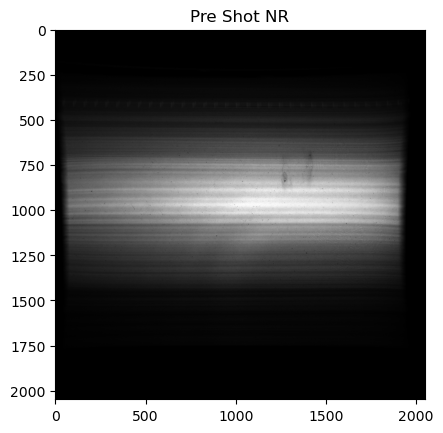

In [4]:
streak_nr_corrected = open_hdf4("/home/timoney/scratch/timoney/MagShockZ/LIONZ_analysis/data_shot3_raw/streak/corrected/leg1-preshot-nr-corrected.hdf")
streak_r_corrected = open_hdf4("/home/timoney/scratch/timoney/MagShockZ/LIONZ_analysis/data_shot3_raw/streak/corrected/leg1-preshot-r-corrected.hdf")

plt.imshow(streak_nr_corrected, cmap='gray')
# show that there are time fiducials - set max to 70
cmax_pre = np.percentile(streak_nr_corrected, 100)
plt.clim(0, cmax_pre)

print(streak_nr_corrected.shape)

plt.title('Pre Shot NR')
plt.show()

Text(0.5, 1.0, 'Shot Image')

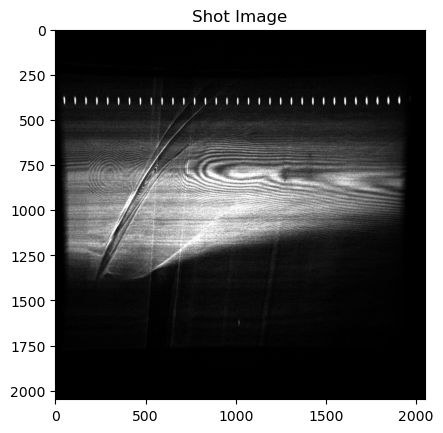

In [5]:
plt.imshow(streak, cmap='gray')
cmax = np.percentile(streak, 99)
plt.clim(0, cmax)
plt.title('Shot Image')

In [6]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]
print(px_to_mm)

0.0111469960824503


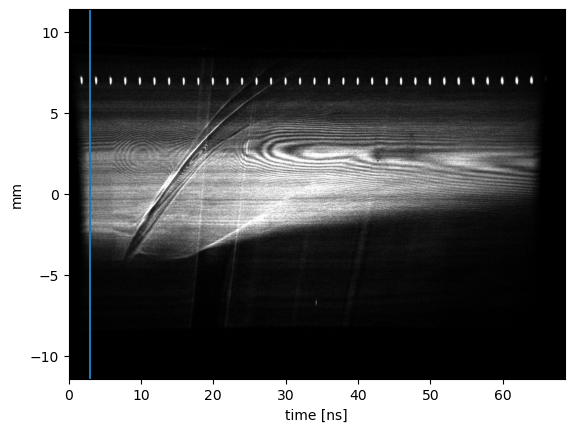

In [7]:
extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')
plt.axvline(3)

plt.savefig('streak_images/streak.jpg', bbox_inches = 'tight')

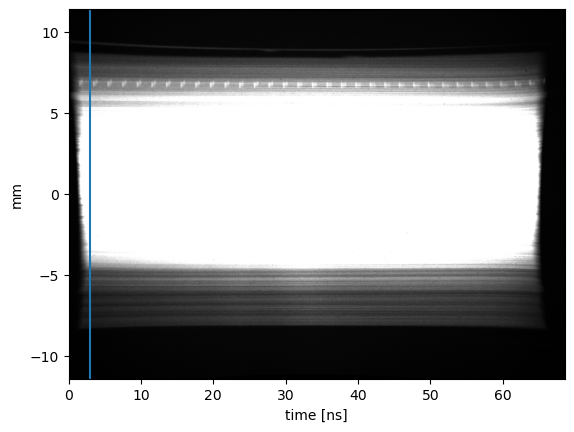

In [8]:
extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak_nr_corrected, cmap = 'grey', extent=ext, aspect='auto')
cmax_pre = np.percentile(streak_nr_corrected, 60)
plt.clim(0, cmax_pre)
plt.xlabel('time [ns]')
plt.ylabel('mm')
plt.axvline(3)

plt.savefig('streak_images/streak_pre.jpg', bbox_inches = 'tight')

Text(0, 0.5, 'mm')

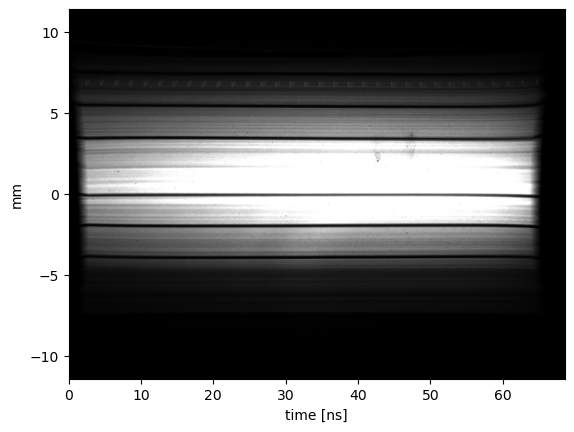

In [9]:
extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak_r_corrected, cmap = 'grey', extent=ext, aspect='auto')
cmax_pre = np.percentile(streak_r_corrected, 90)
plt.clim(0, cmax_pre)
plt.xlabel('time [ns]')
plt.ylabel('mm')
# plt.axvline(3)

# plt.savefig('streak_images/streak_pre.jpg', bbox_inches = 'tight')

In [10]:
times_bkgd = np.linspace(3, 5, 101)
times_bkgd = np.array(times_bkgd)
pos_bkgd = []
lineouts_bkgd = []
for t in times_bkgd:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image = streak_nr_corrected, return_data = True, plot = False, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_bkgd.append(lo)
    pos_bkgd.append(y)
pos_bkgd = np.array(pos_bkgd)
lineouts_bkgd = np.array(lineouts_bkgd, dtype=object)

mask = (times_bkgd < 4.0) & (times_bkgd > 3.5)
times_bkgd_ret = times_bkgd[mask]
pos_bkgd_ret = pos_bkgd[mask]
lineouts_bkgd_ret = lineouts_bkgd[mask]

In [11]:
background = np.mean(lineouts_bkgd, axis = 0)

In [12]:
times_bkgd_img = np.linspace(3, 5, 101)
times_bkgd_img = np.array(times_bkgd_img)
pos_bkgd_img = []
lineouts_bkgd_img = []
for t in times_bkgd_img:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image = streak, return_data = True, plot = False, output = f'streak_images/lineouts/img_linout_t={t}ns.jpg')
    lineouts_bkgd_img.append(lo)
    pos_bkgd_img.append(y)
pos_bkgd_img = np.array(pos_bkgd_img)
lineouts_bkgd_img = np.array(lineouts_bkgd_img, dtype=object)

mask_ret = (times_bkgd_img < 4.0) & (times_bkgd_img > 3.5)
times_bkgd_img_ret = times_bkgd_img[mask_ret]
pos_bkgd_img_ret = pos_bkgd_img[mask_ret]
lineouts_bkgd_img_ret = lineouts_bkgd_img[mask_ret]

Pre shot time: 3.0
Shot image time: 3.0


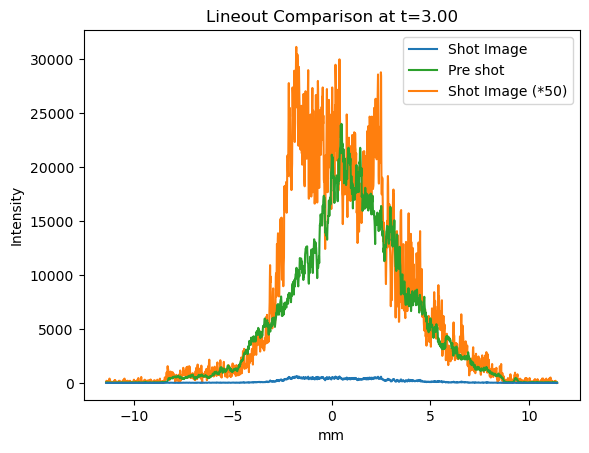

Pre shot time: 3.02
Shot image time: 3.02


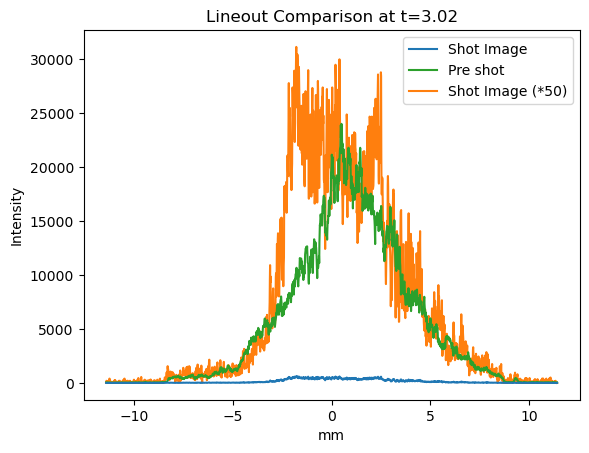

Pre shot time: 3.04
Shot image time: 3.04


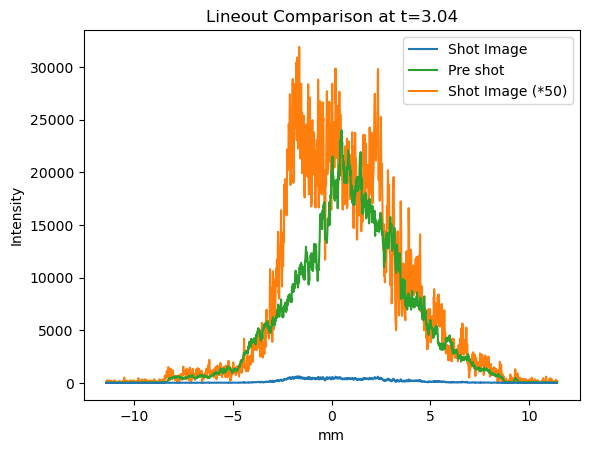

Pre shot time: 3.06
Shot image time: 3.06


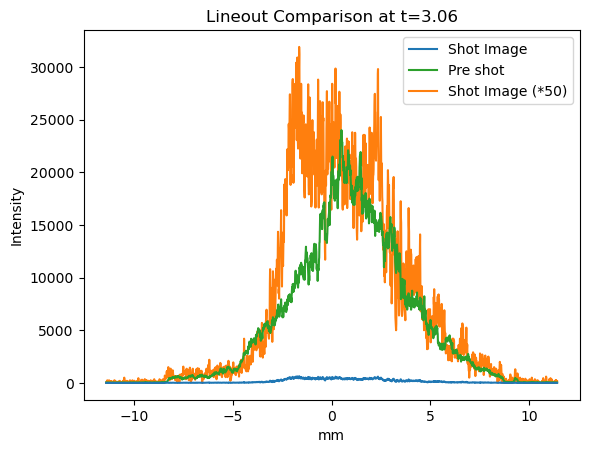

Pre shot time: 3.08
Shot image time: 3.08


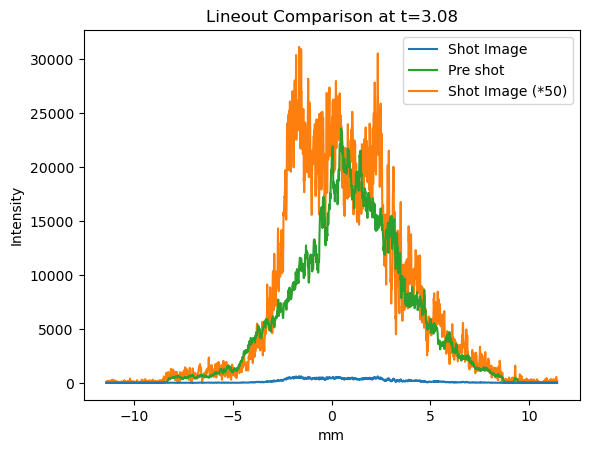

Pre shot time: 3.1
Shot image time: 3.1


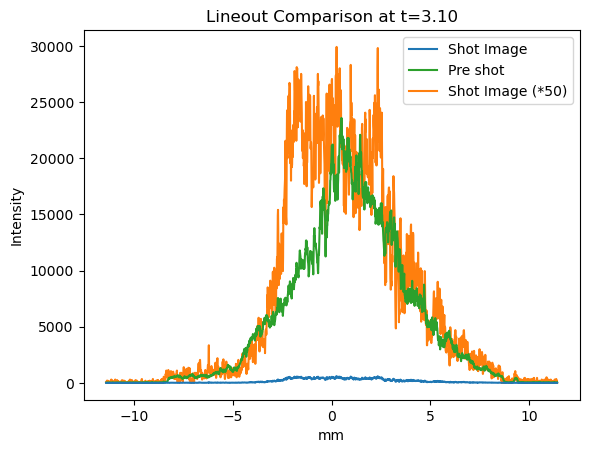

Pre shot time: 3.12
Shot image time: 3.12


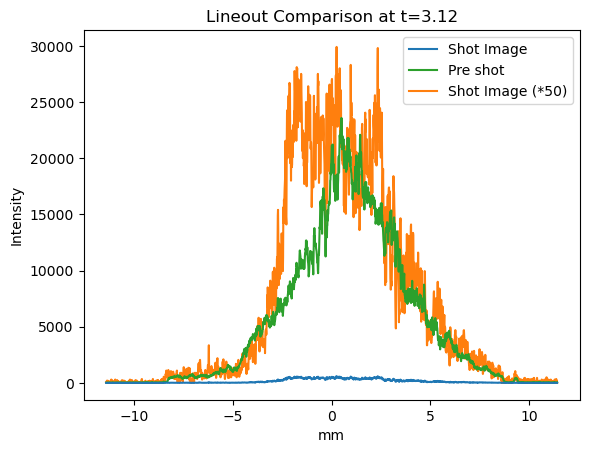

Pre shot time: 3.14
Shot image time: 3.14


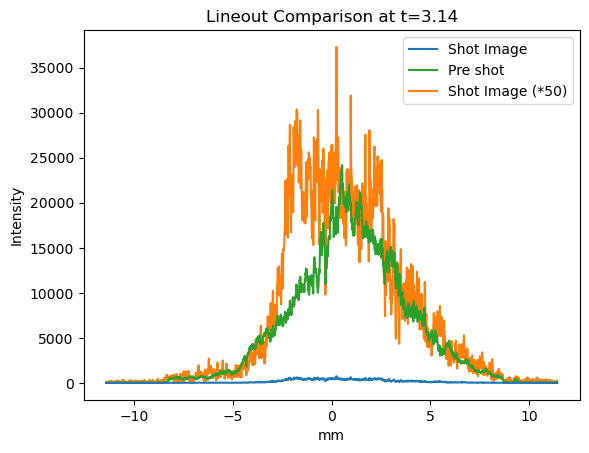

Pre shot time: 3.16
Shot image time: 3.16


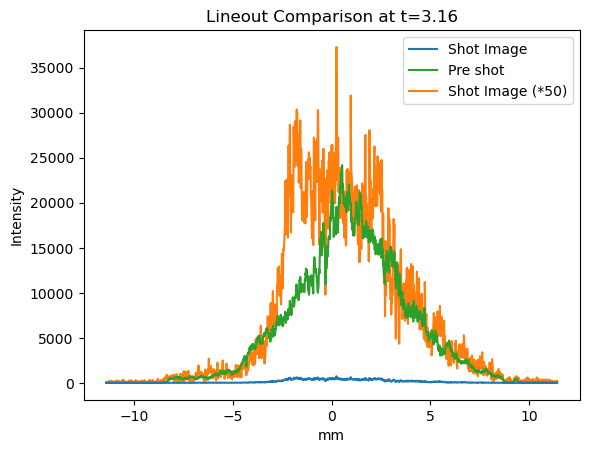

Pre shot time: 3.18
Shot image time: 3.18


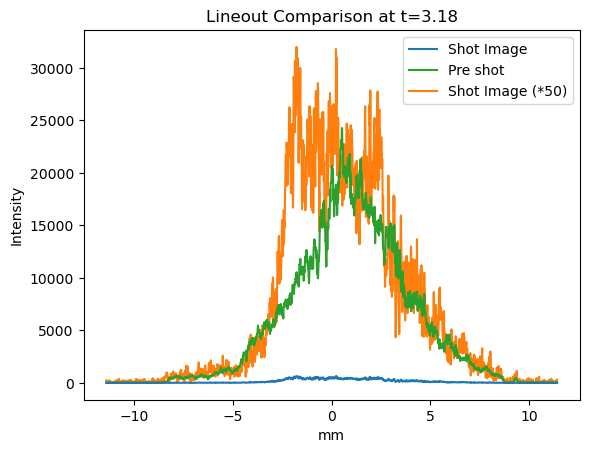

Pre shot time: 3.2
Shot image time: 3.2


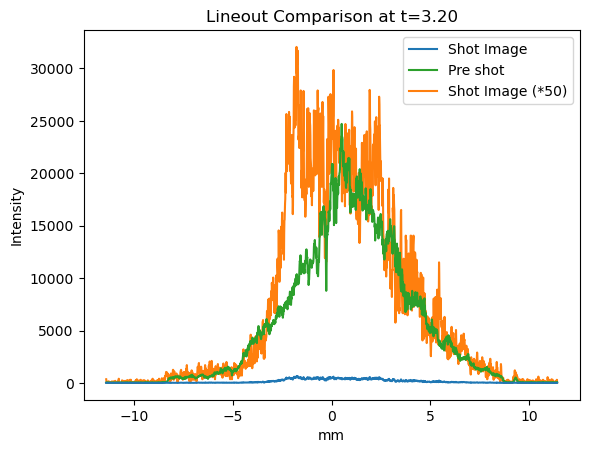

Pre shot time: 3.22
Shot image time: 3.22


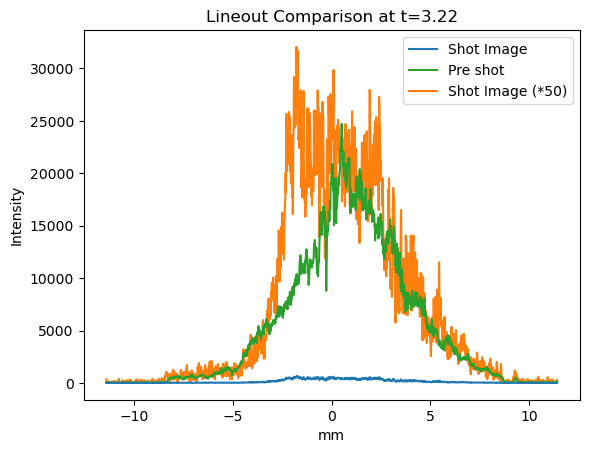

Pre shot time: 3.24
Shot image time: 3.24


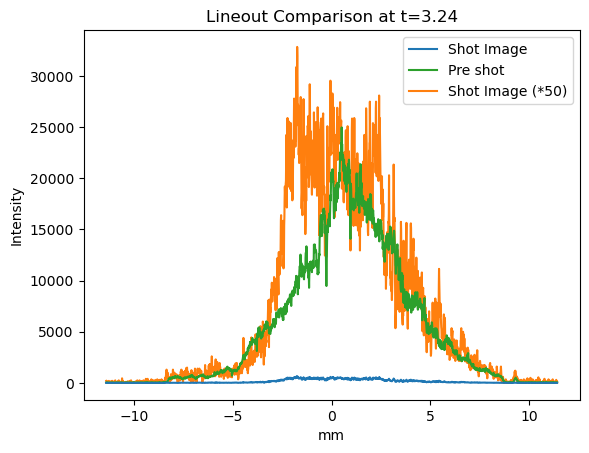

Pre shot time: 3.26
Shot image time: 3.26


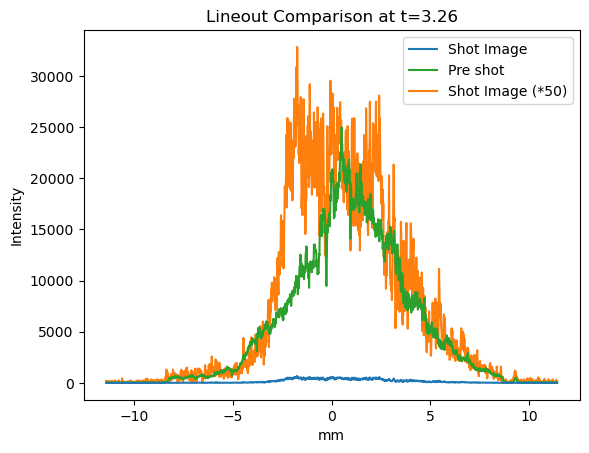

Pre shot time: 3.2800000000000002
Shot image time: 3.2800000000000002


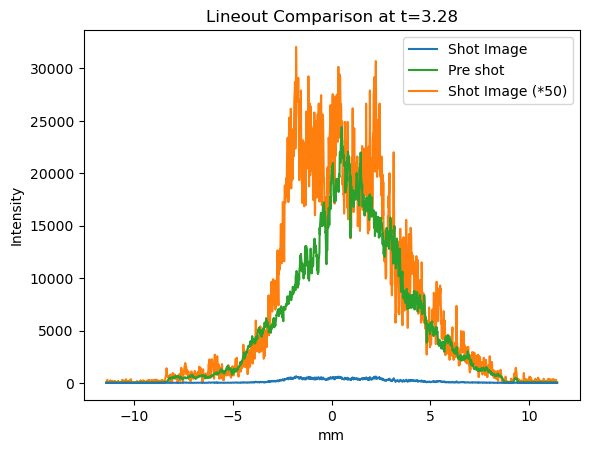

Pre shot time: 3.3
Shot image time: 3.3


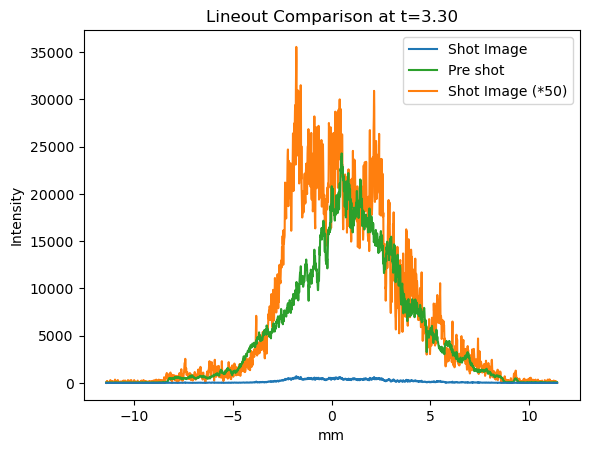

Pre shot time: 3.32
Shot image time: 3.32


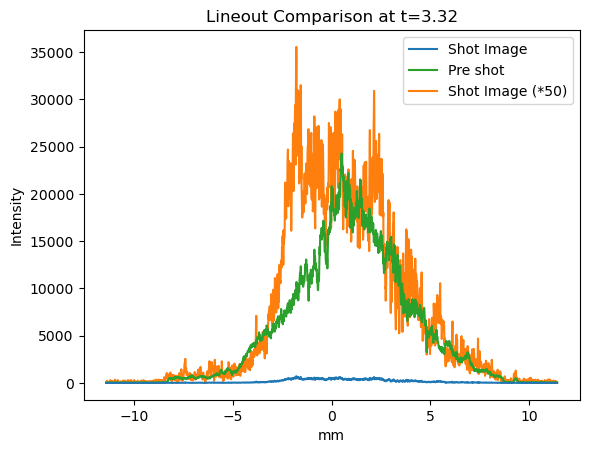

Pre shot time: 3.34
Shot image time: 3.34


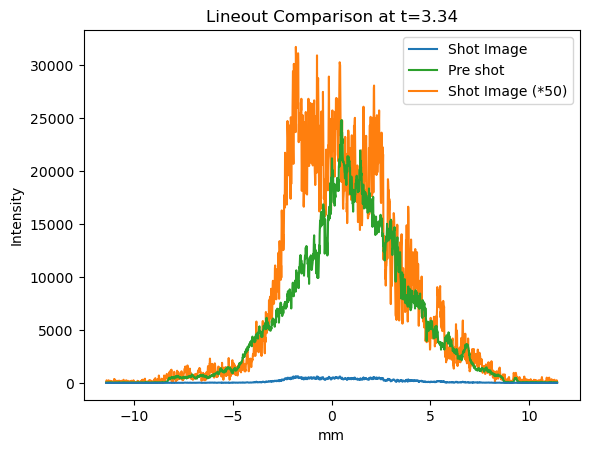

Pre shot time: 3.36
Shot image time: 3.36


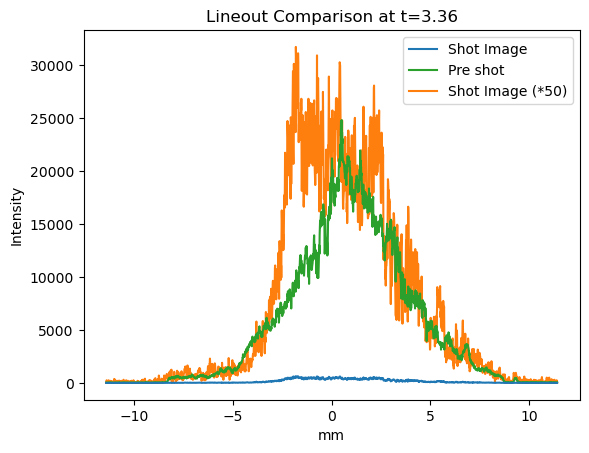

Pre shot time: 3.38
Shot image time: 3.38


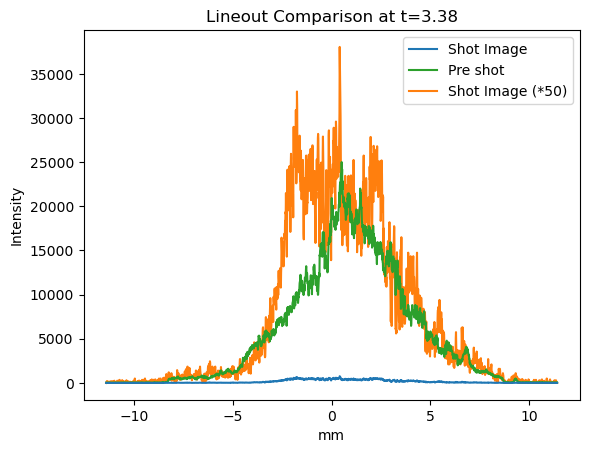

Pre shot time: 3.4
Shot image time: 3.4


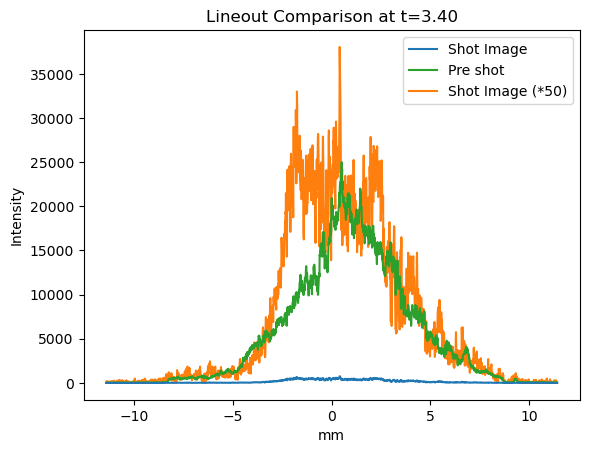

Pre shot time: 3.42
Shot image time: 3.42


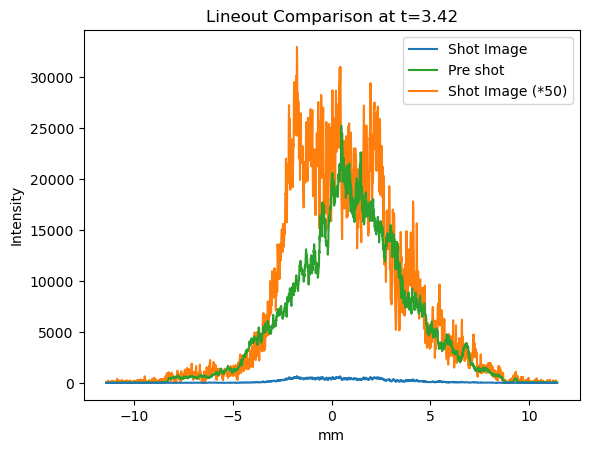

Pre shot time: 3.44
Shot image time: 3.44


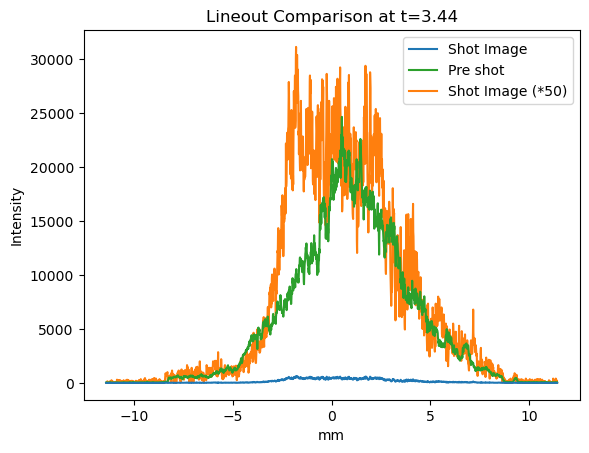

Pre shot time: 3.46
Shot image time: 3.46


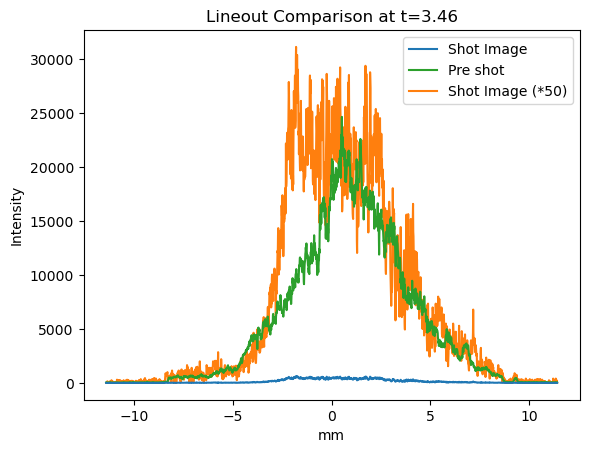

Pre shot time: 3.48
Shot image time: 3.48


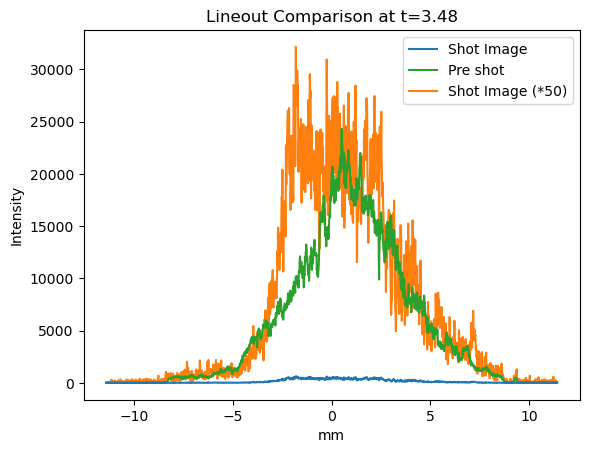

Pre shot time: 3.5
Shot image time: 3.5


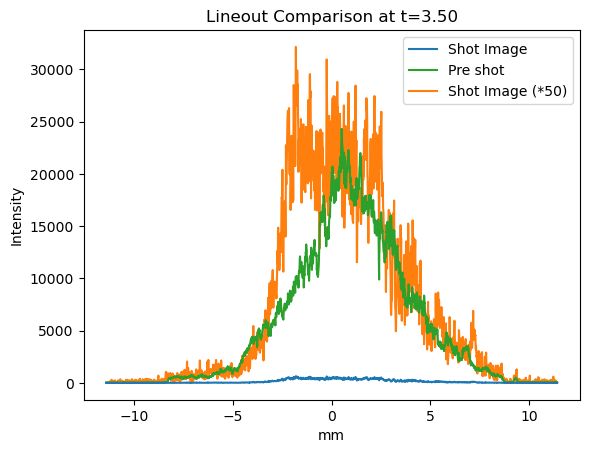

Pre shot time: 3.52
Shot image time: 3.52


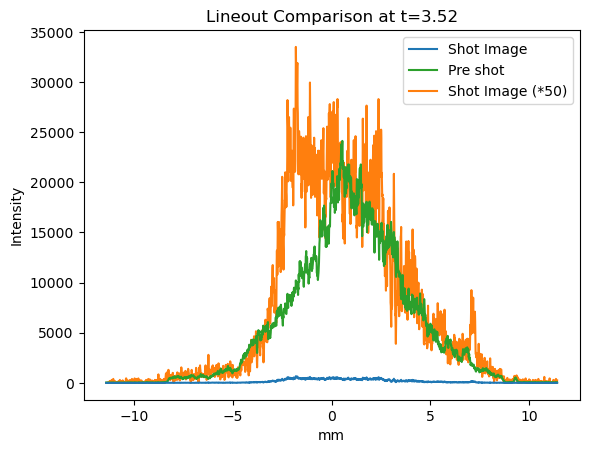

Pre shot time: 3.54
Shot image time: 3.54


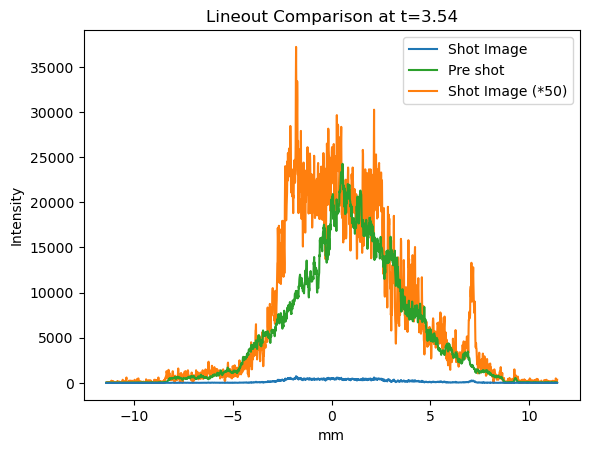

Pre shot time: 3.56
Shot image time: 3.56


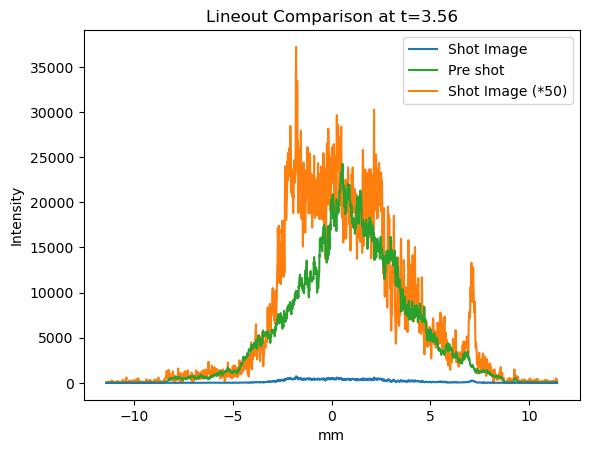

Pre shot time: 3.58
Shot image time: 3.58


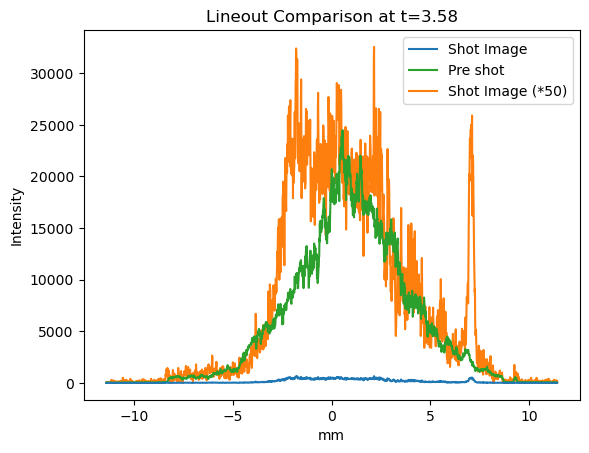

Pre shot time: 3.6
Shot image time: 3.6


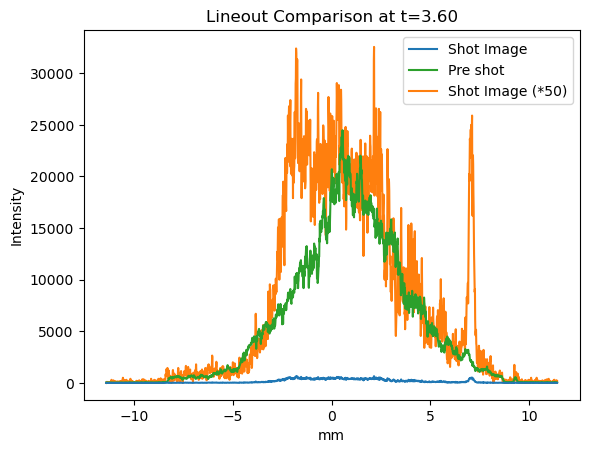

Pre shot time: 3.62
Shot image time: 3.62


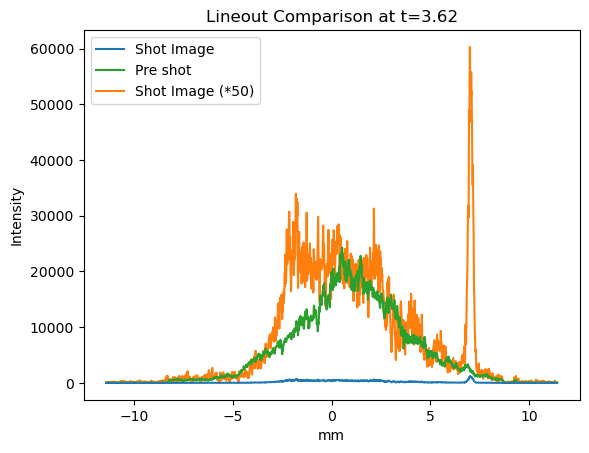

Pre shot time: 3.64
Shot image time: 3.64


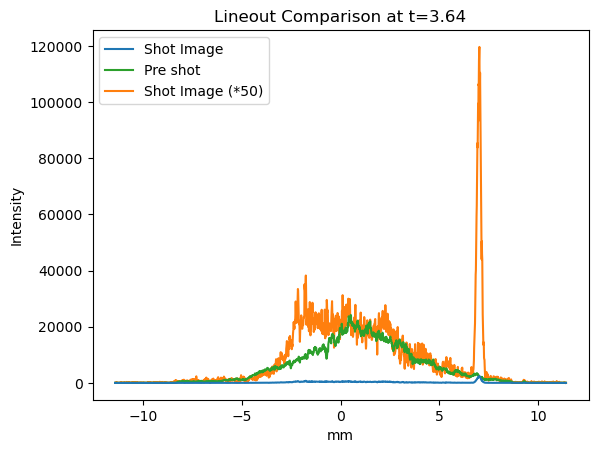

Pre shot time: 3.66
Shot image time: 3.66


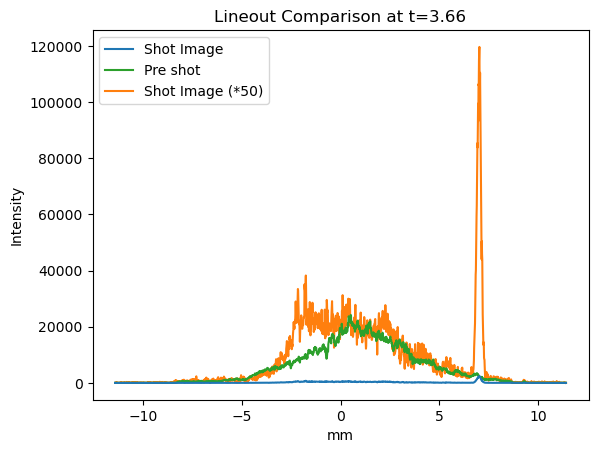

Pre shot time: 3.68
Shot image time: 3.68


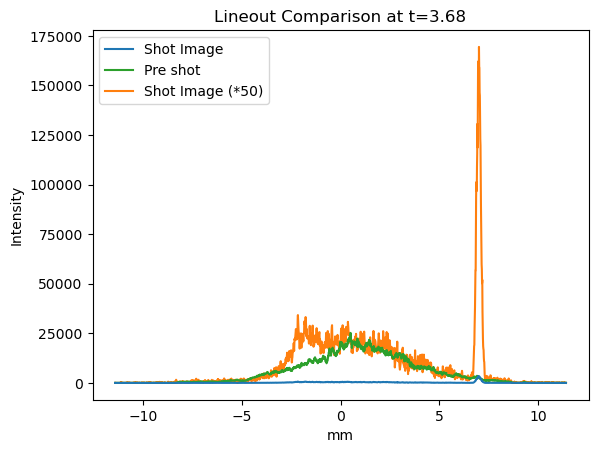

Pre shot time: 3.7
Shot image time: 3.7


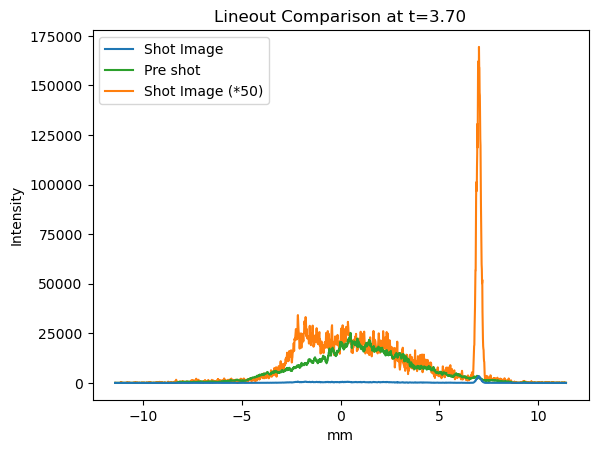

Pre shot time: 3.7199999999999998
Shot image time: 3.7199999999999998


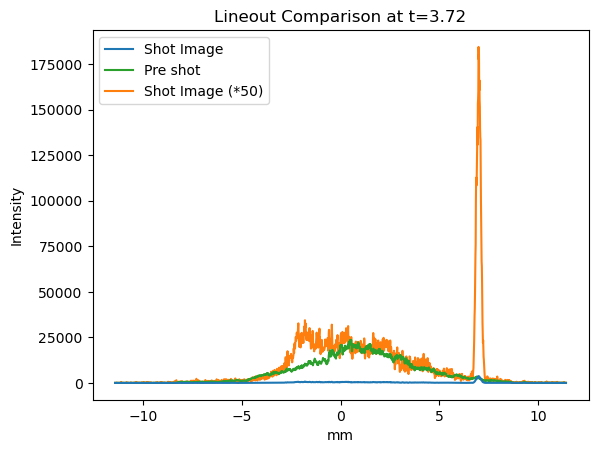

Pre shot time: 3.74
Shot image time: 3.74


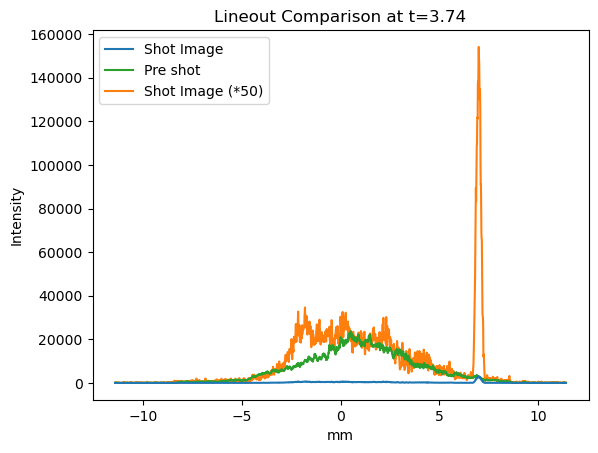

Pre shot time: 3.76
Shot image time: 3.76


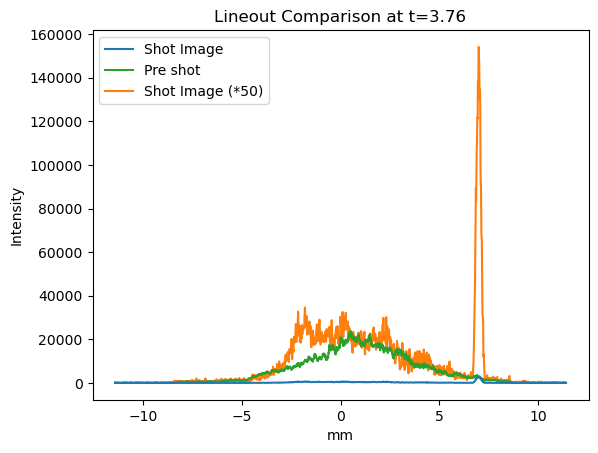

Pre shot time: 3.7800000000000002
Shot image time: 3.7800000000000002


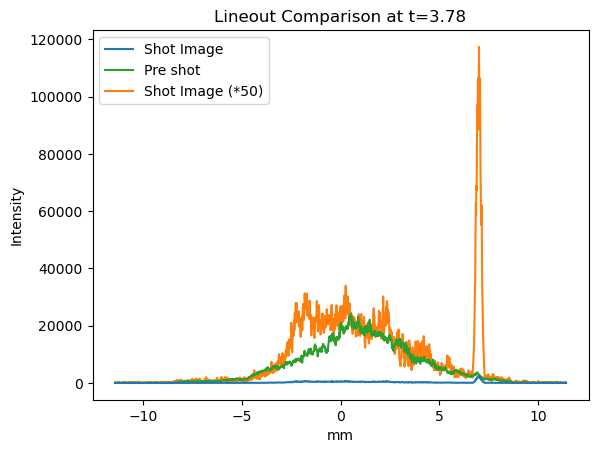

Pre shot time: 3.8
Shot image time: 3.8


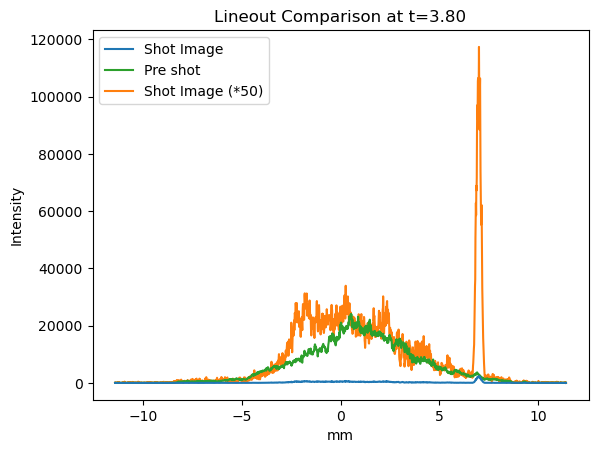

Pre shot time: 3.8200000000000003
Shot image time: 3.8200000000000003


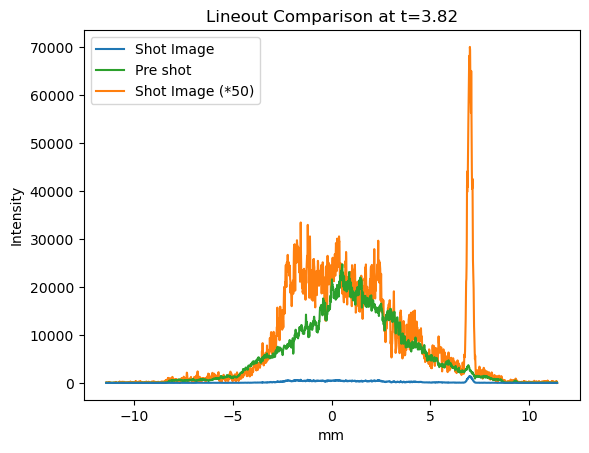

Pre shot time: 3.84
Shot image time: 3.84


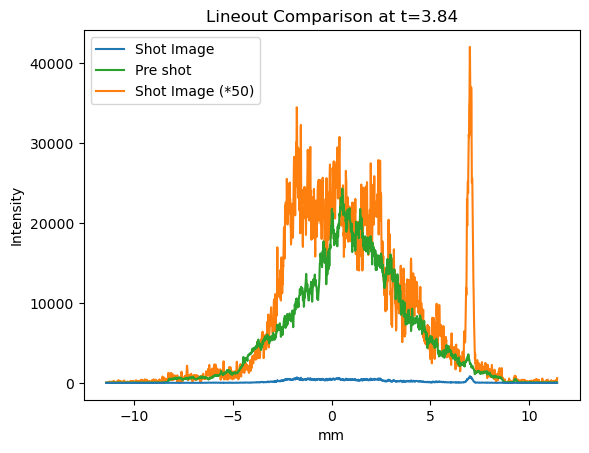

Pre shot time: 3.86
Shot image time: 3.86


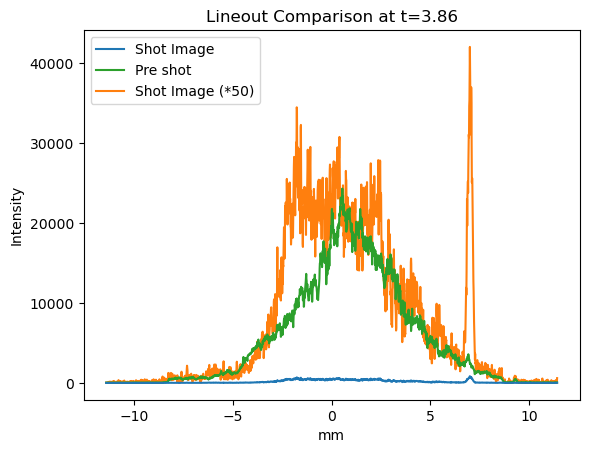

Pre shot time: 3.88
Shot image time: 3.88


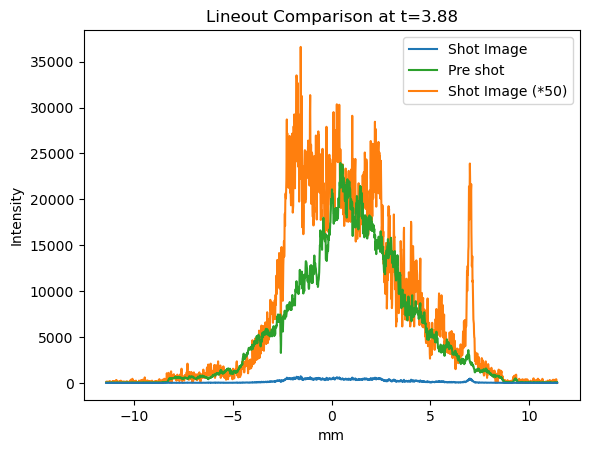

Pre shot time: 3.9
Shot image time: 3.9


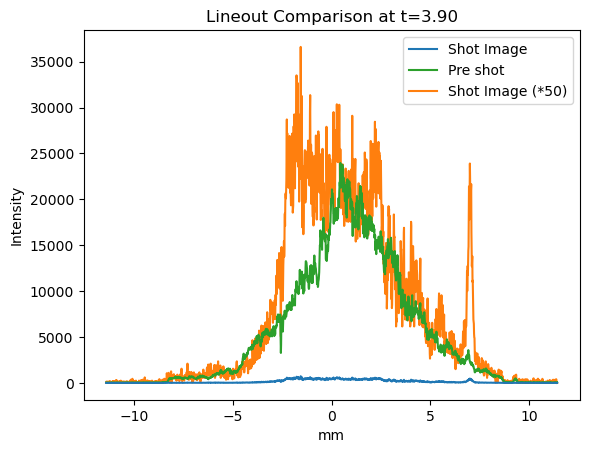

Pre shot time: 3.92
Shot image time: 3.92


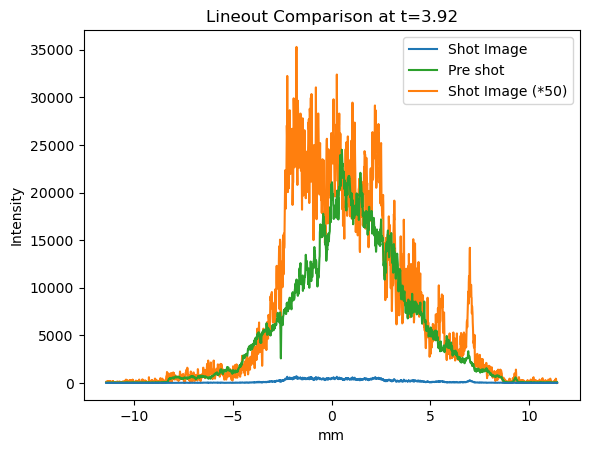

Pre shot time: 3.94
Shot image time: 3.94


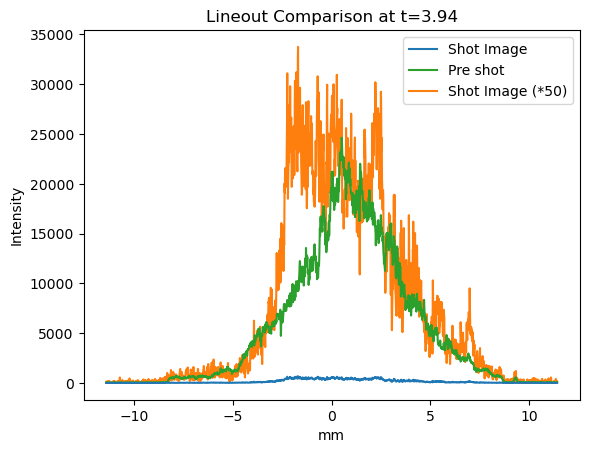

Pre shot time: 3.96
Shot image time: 3.96


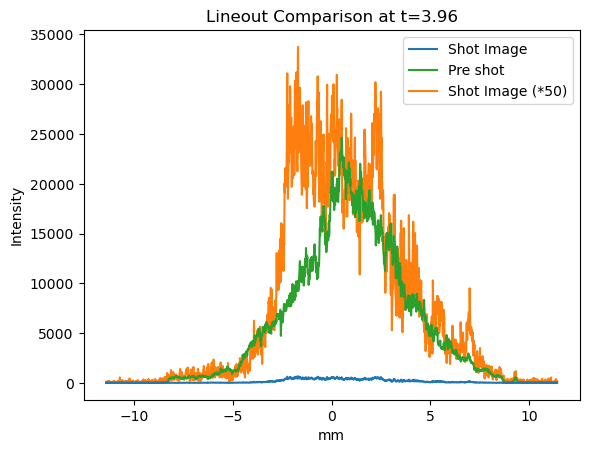

Pre shot time: 3.98
Shot image time: 3.98


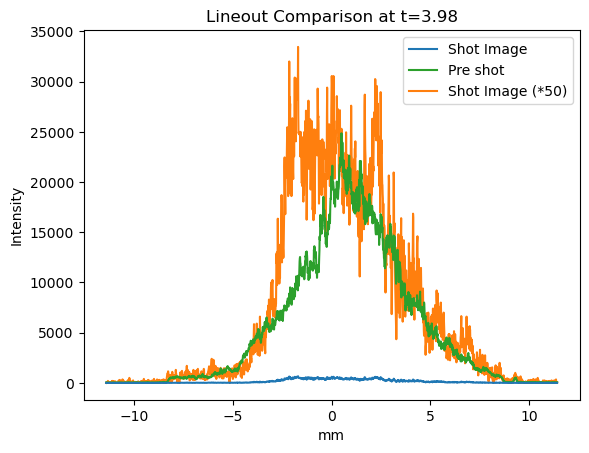

Pre shot time: 4.0
Shot image time: 4.0


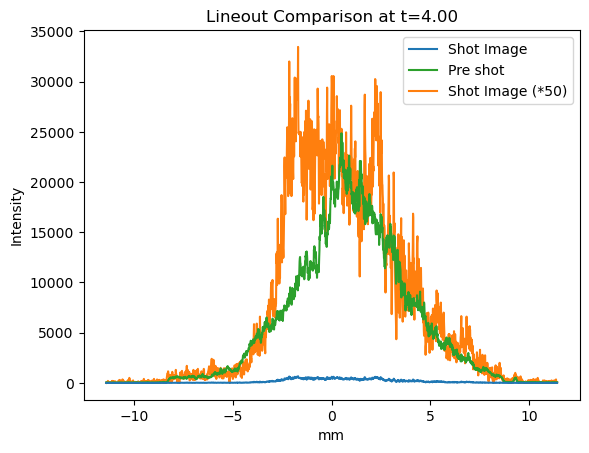

Pre shot time: 4.02
Shot image time: 4.02


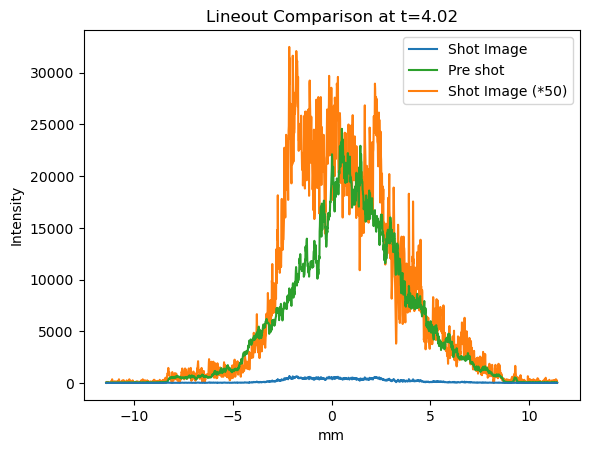

Pre shot time: 4.04
Shot image time: 4.04


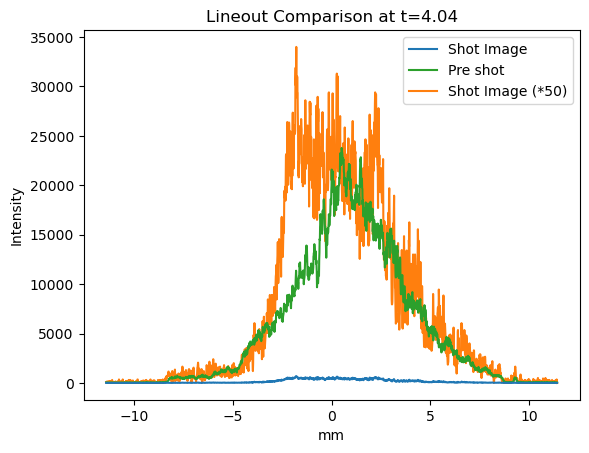

Pre shot time: 4.0600000000000005
Shot image time: 4.0600000000000005


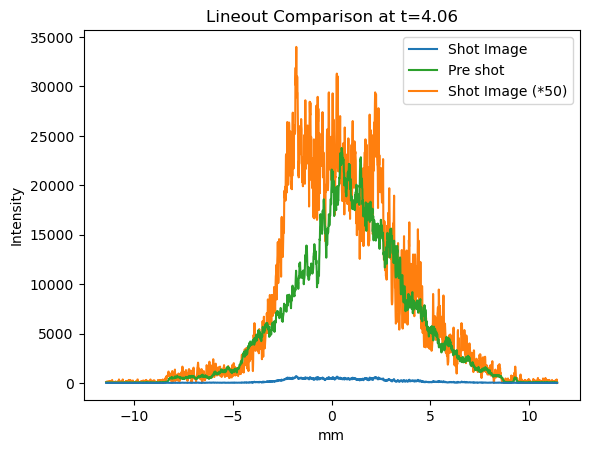

Pre shot time: 4.08
Shot image time: 4.08


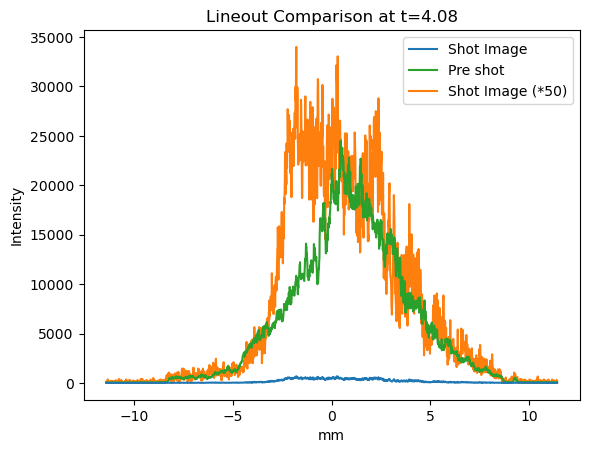

Pre shot time: 4.1
Shot image time: 4.1


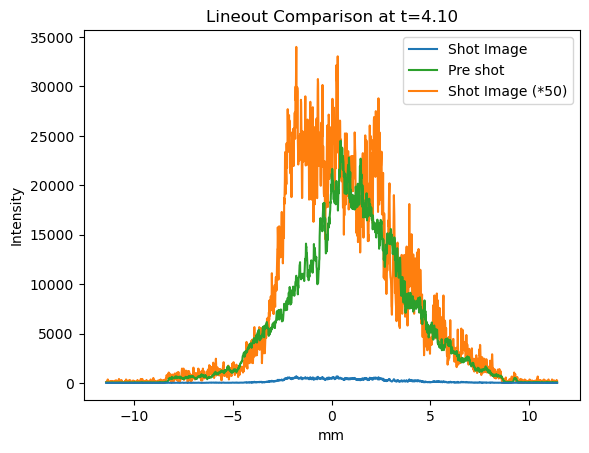

Pre shot time: 4.12
Shot image time: 4.12


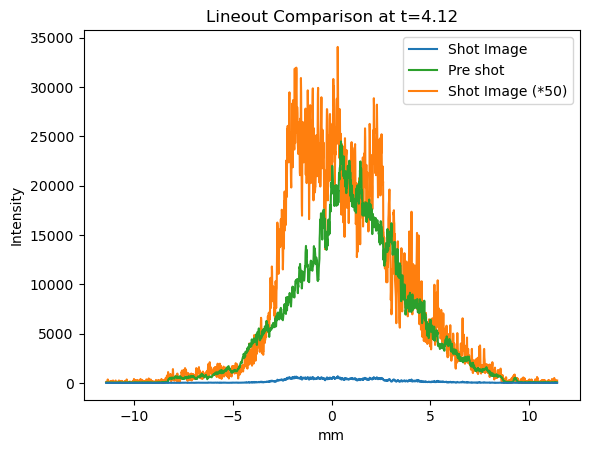

Pre shot time: 4.140000000000001
Shot image time: 4.140000000000001


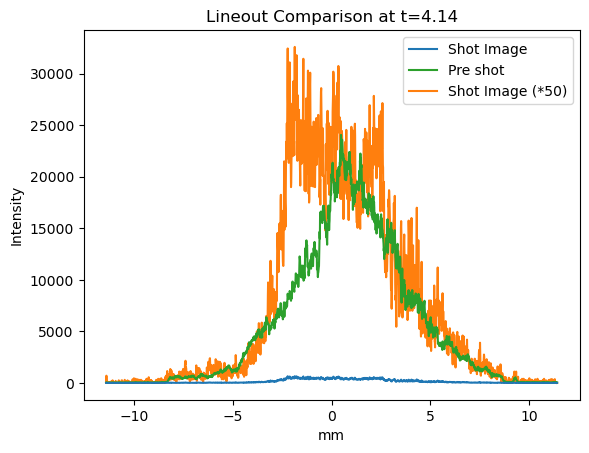

Pre shot time: 4.16
Shot image time: 4.16


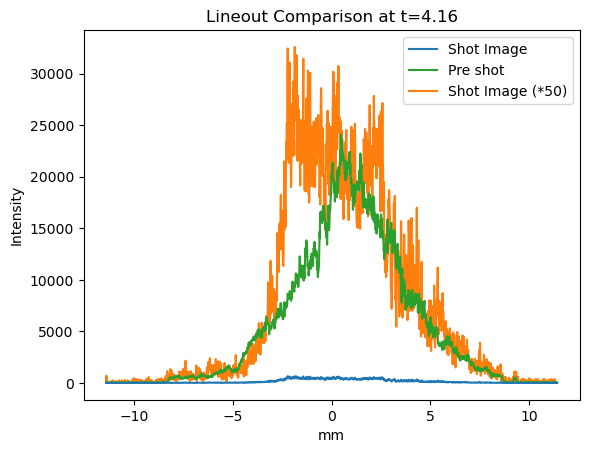

Pre shot time: 4.18
Shot image time: 4.18


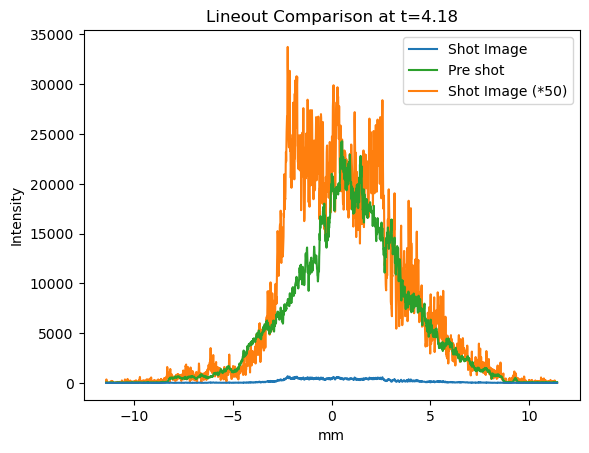

Pre shot time: 4.2
Shot image time: 4.2


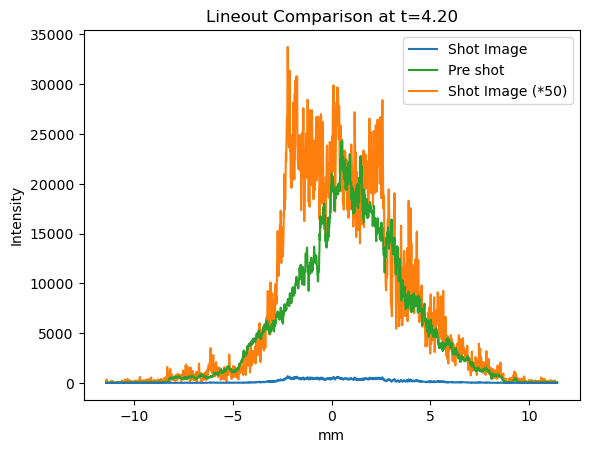

Pre shot time: 4.22
Shot image time: 4.22


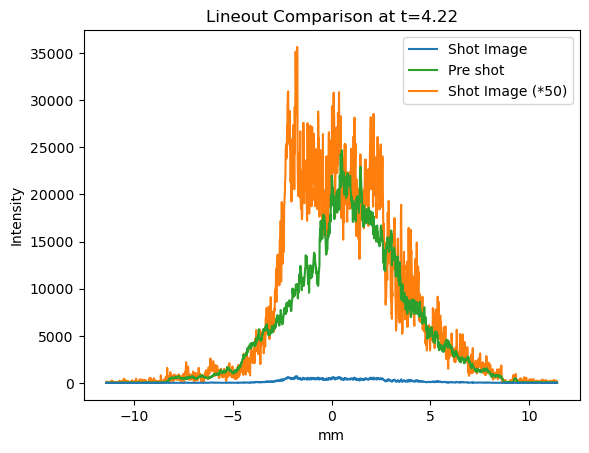

Pre shot time: 4.24
Shot image time: 4.24


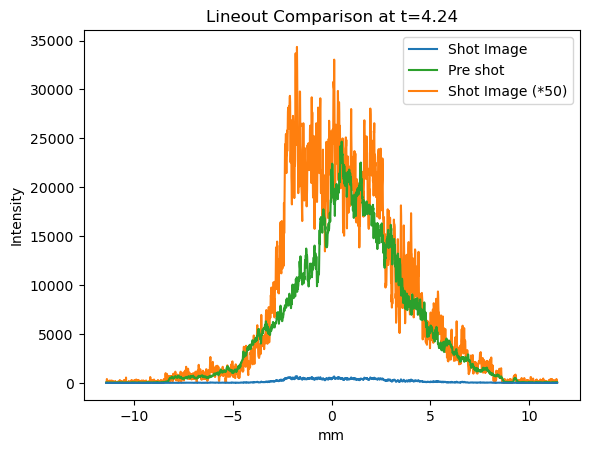

Pre shot time: 4.26
Shot image time: 4.26


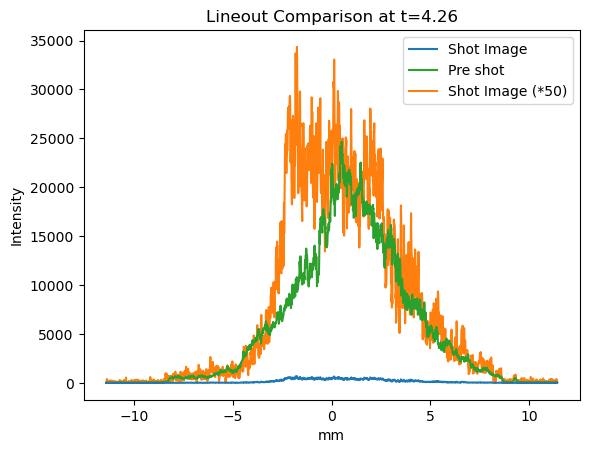

Pre shot time: 4.28
Shot image time: 4.28


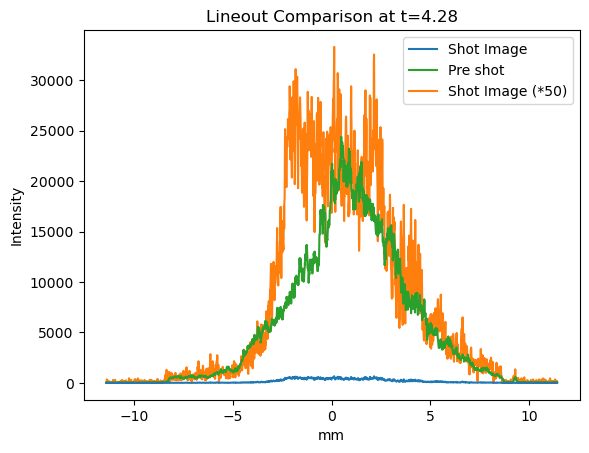

Pre shot time: 4.3
Shot image time: 4.3


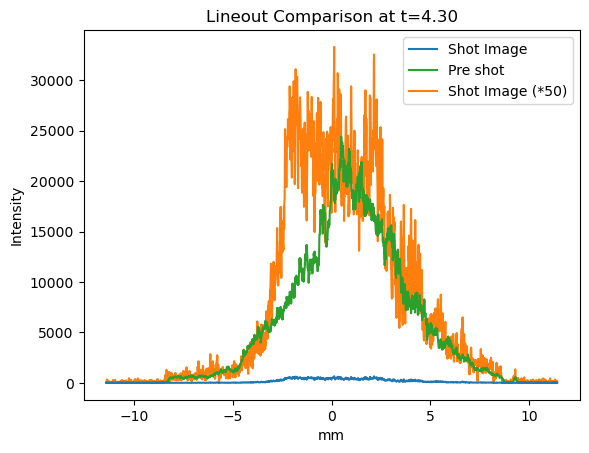

Pre shot time: 4.32
Shot image time: 4.32


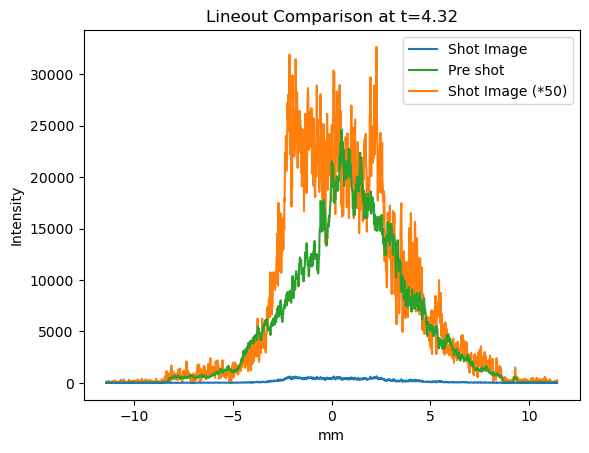

Pre shot time: 4.34
Shot image time: 4.34


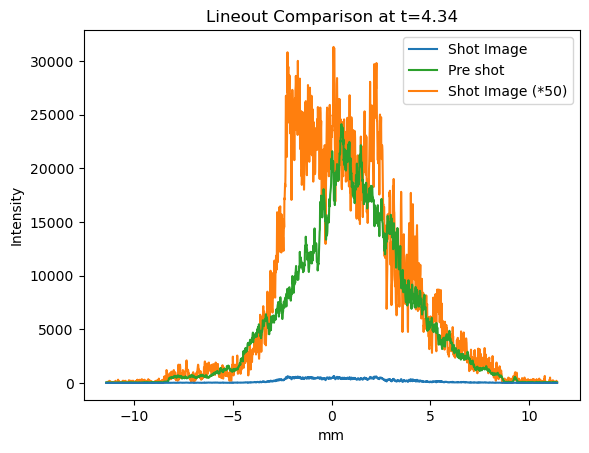

Pre shot time: 4.36
Shot image time: 4.36


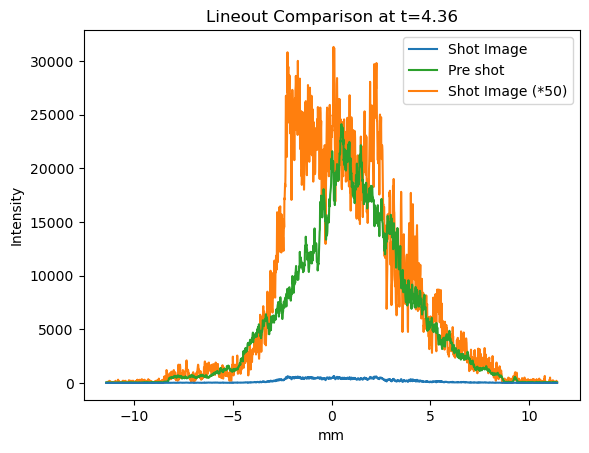

Pre shot time: 4.38
Shot image time: 4.38


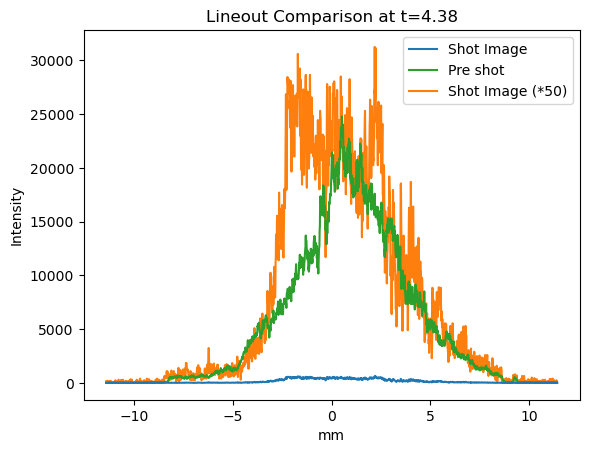

Pre shot time: 4.4
Shot image time: 4.4


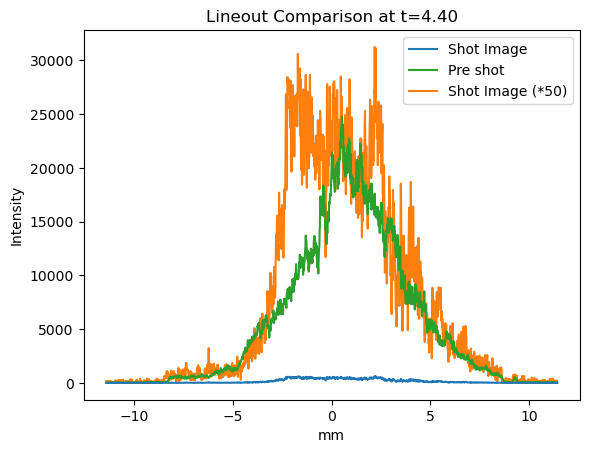

Pre shot time: 4.42
Shot image time: 4.42


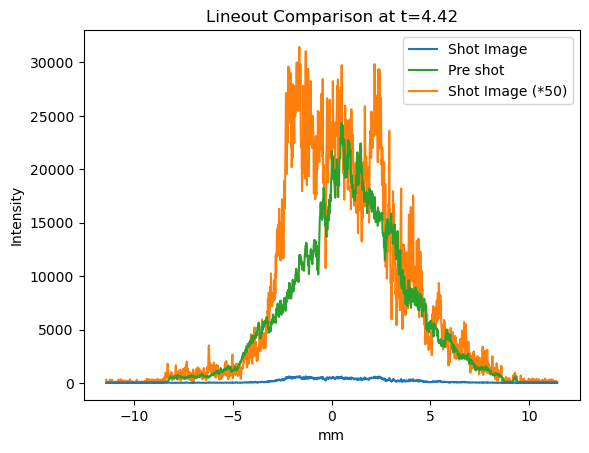

Pre shot time: 4.4399999999999995
Shot image time: 4.4399999999999995


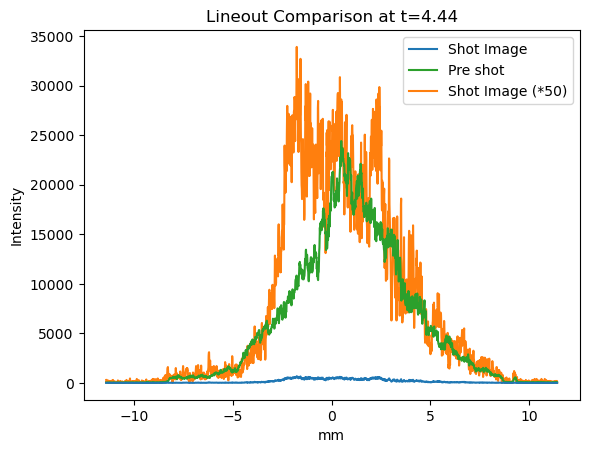

Pre shot time: 4.46
Shot image time: 4.46


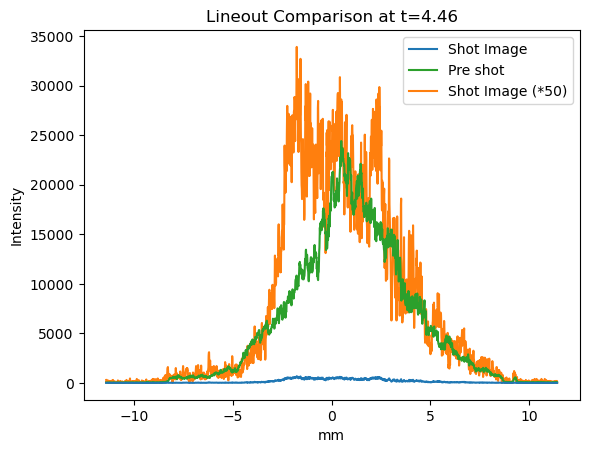

Pre shot time: 4.48
Shot image time: 4.48


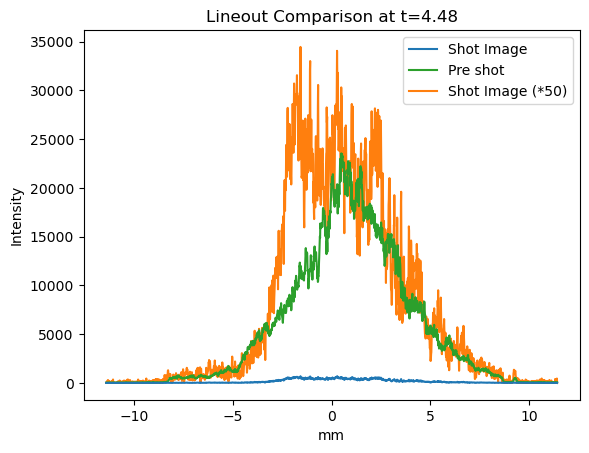

Pre shot time: 4.5
Shot image time: 4.5


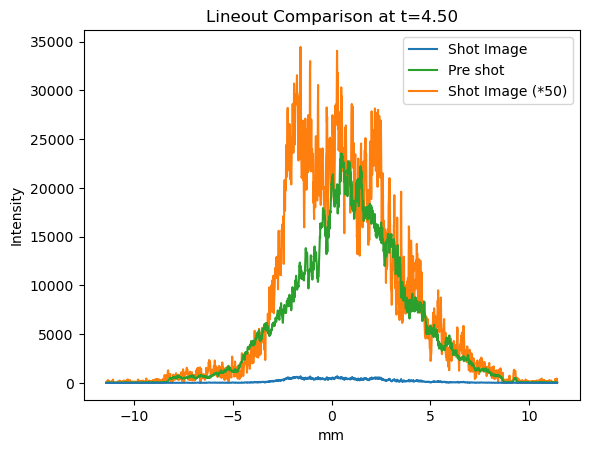

Pre shot time: 4.52
Shot image time: 4.52


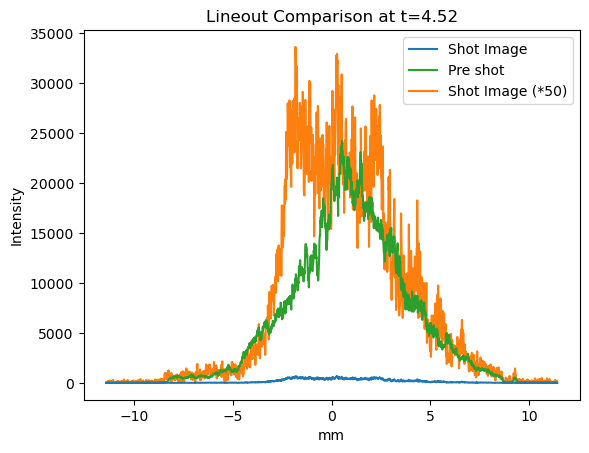

Pre shot time: 4.54
Shot image time: 4.54


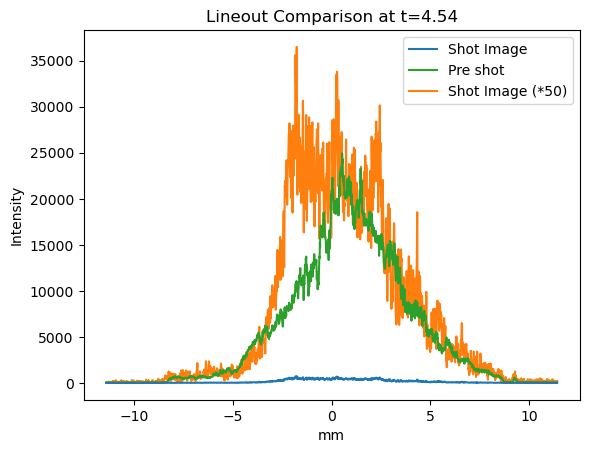

Pre shot time: 4.5600000000000005
Shot image time: 4.5600000000000005


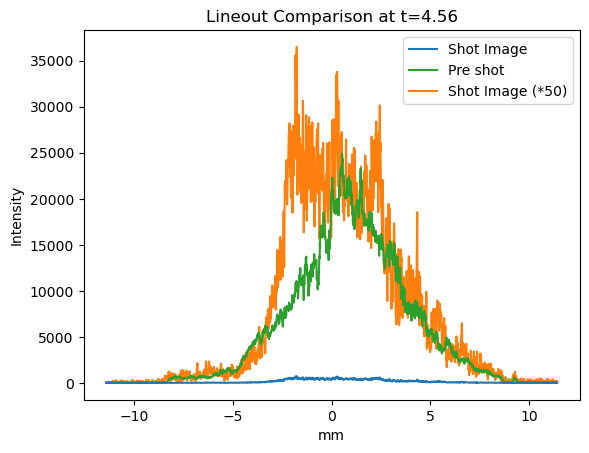

Pre shot time: 4.58
Shot image time: 4.58


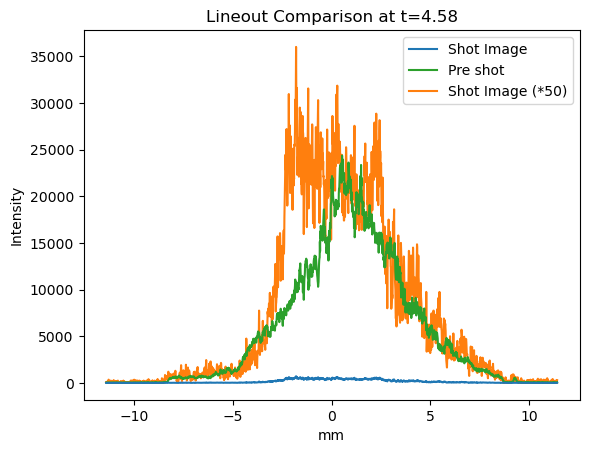

Pre shot time: 4.6
Shot image time: 4.6


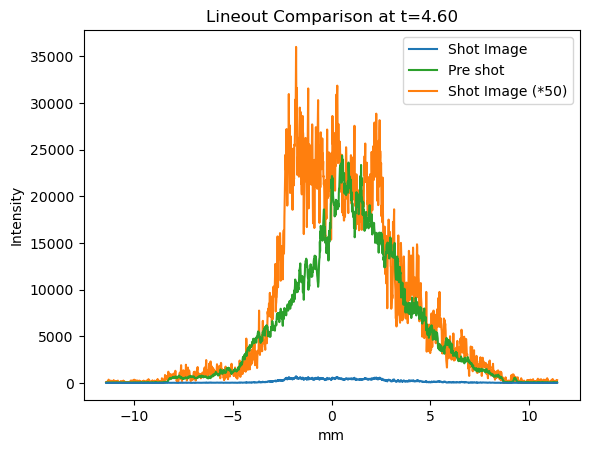

Pre shot time: 4.62
Shot image time: 4.62


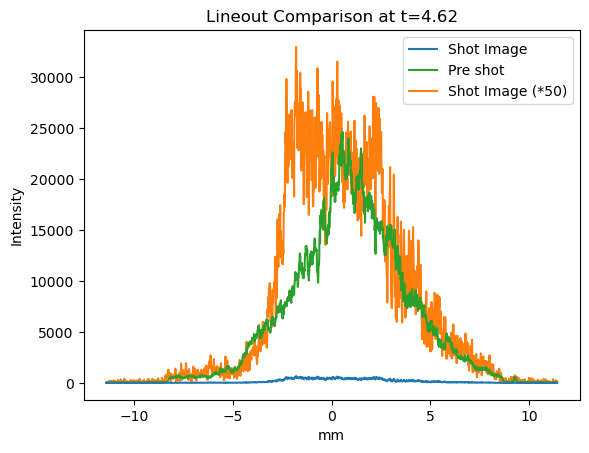

Pre shot time: 4.640000000000001
Shot image time: 4.640000000000001


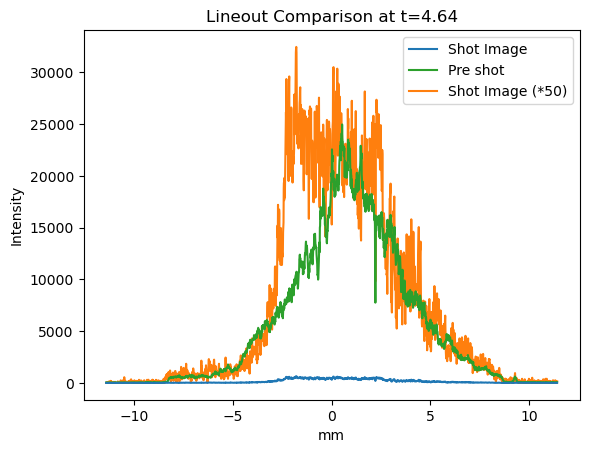

Pre shot time: 4.66
Shot image time: 4.66


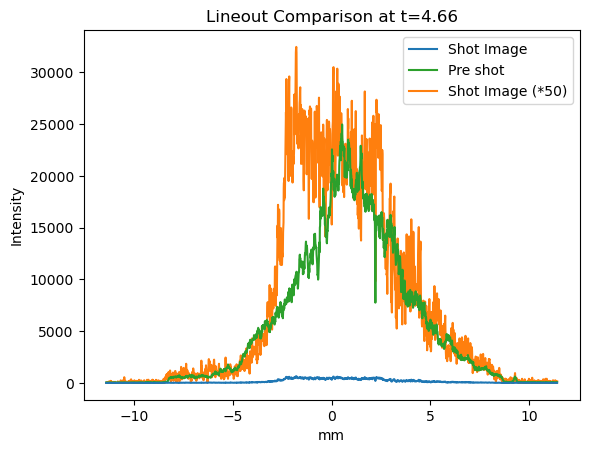

Pre shot time: 4.68
Shot image time: 4.68


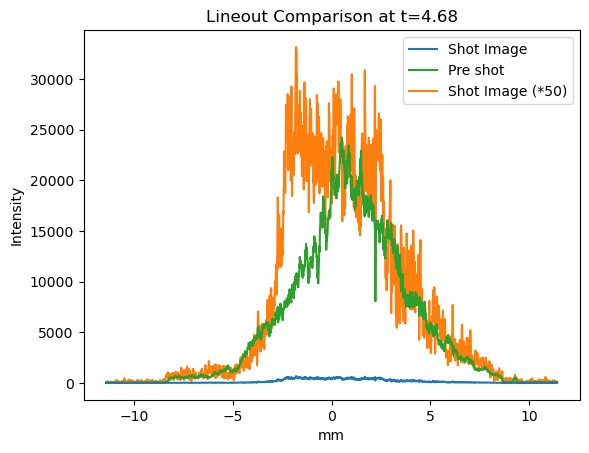

Pre shot time: 4.7
Shot image time: 4.7


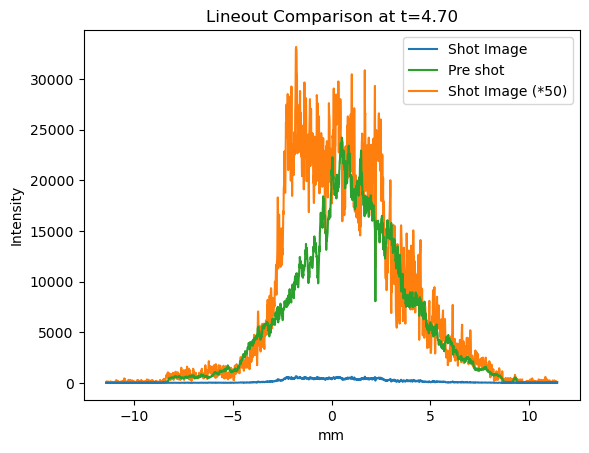

Pre shot time: 4.72
Shot image time: 4.72


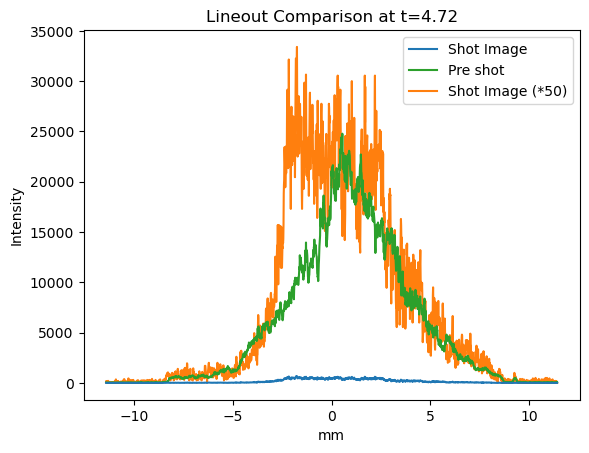

Pre shot time: 4.74
Shot image time: 4.74


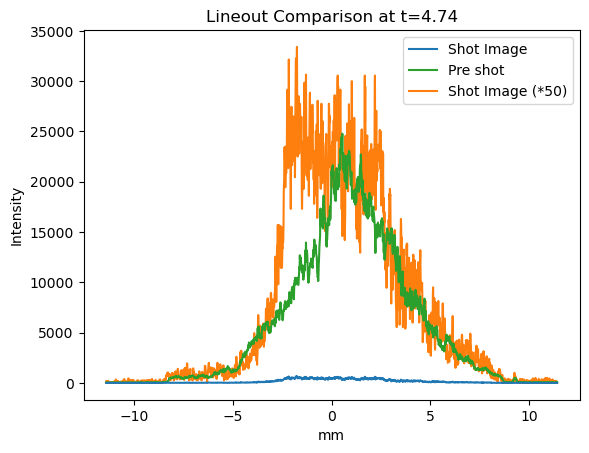

Pre shot time: 4.76
Shot image time: 4.76


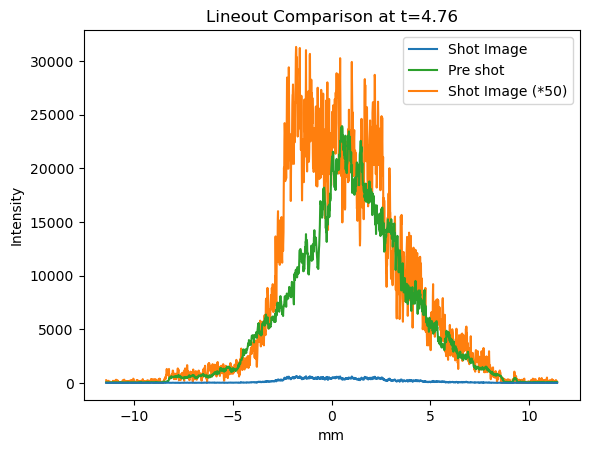

Pre shot time: 4.78
Shot image time: 4.78


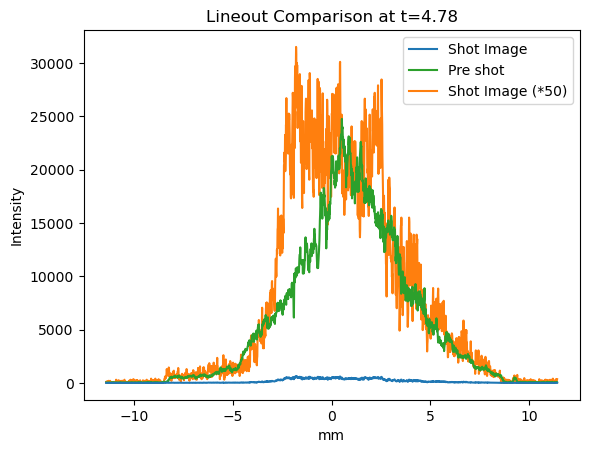

Pre shot time: 4.8
Shot image time: 4.8


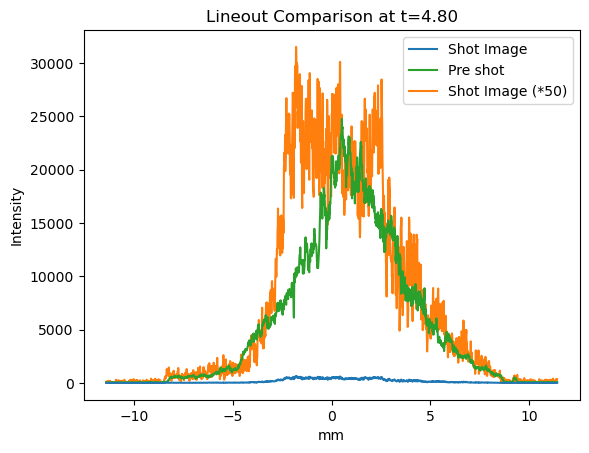

Pre shot time: 4.82
Shot image time: 4.82


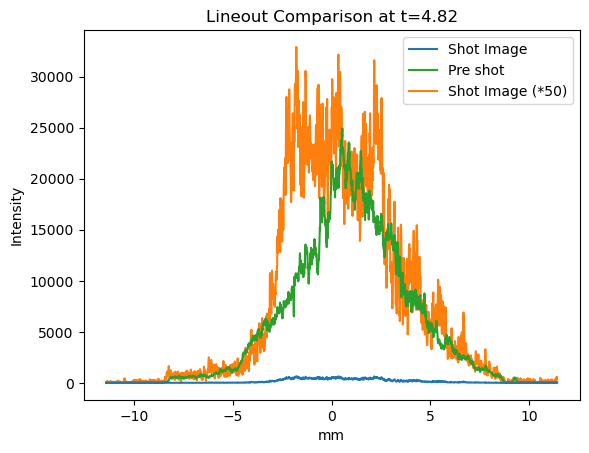

Pre shot time: 4.84
Shot image time: 4.84


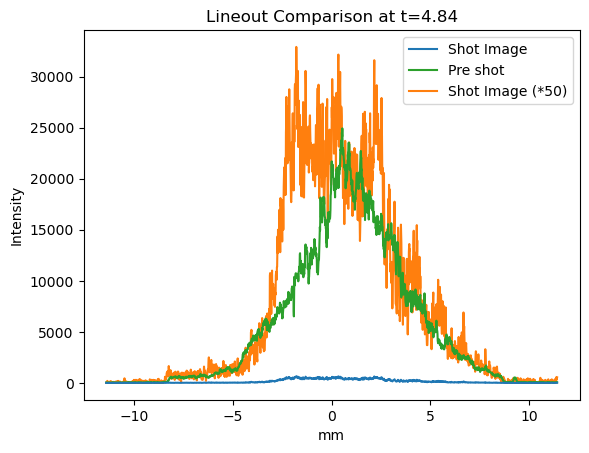

Pre shot time: 4.86
Shot image time: 4.86


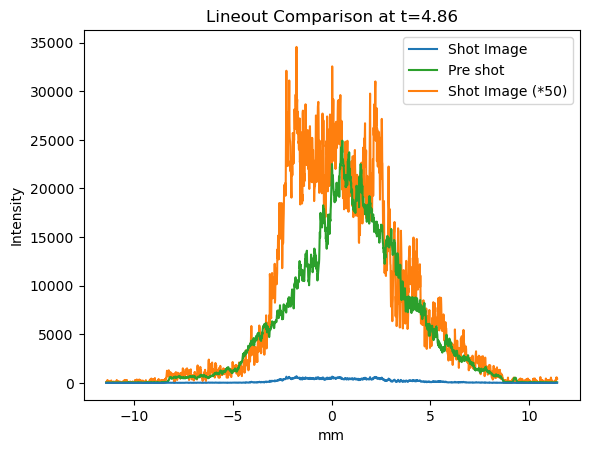

Pre shot time: 4.88
Shot image time: 4.88


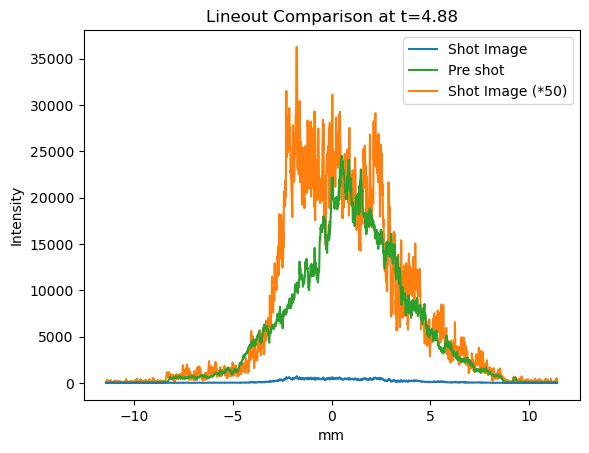

Pre shot time: 4.9
Shot image time: 4.9


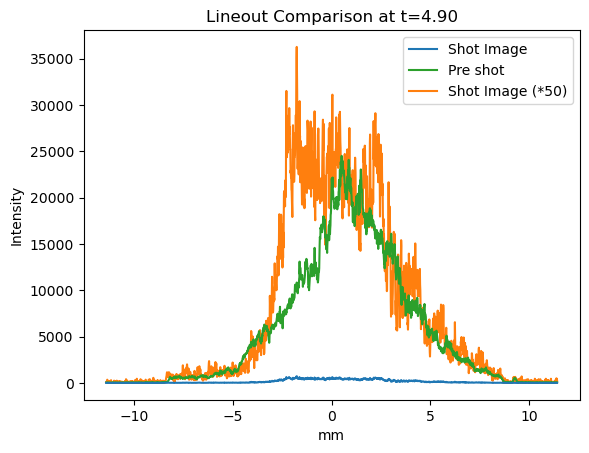

Pre shot time: 4.92
Shot image time: 4.92


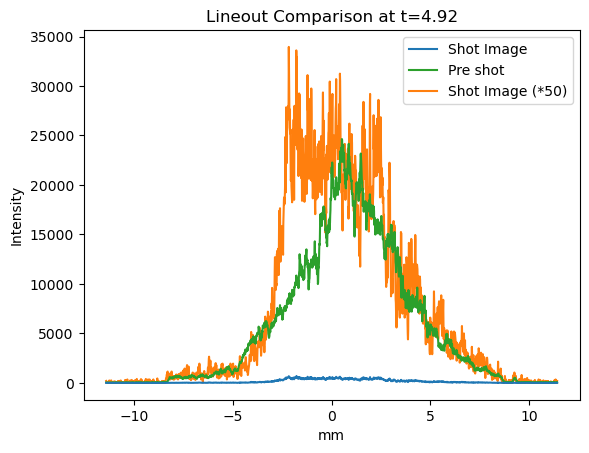

Pre shot time: 4.9399999999999995
Shot image time: 4.9399999999999995


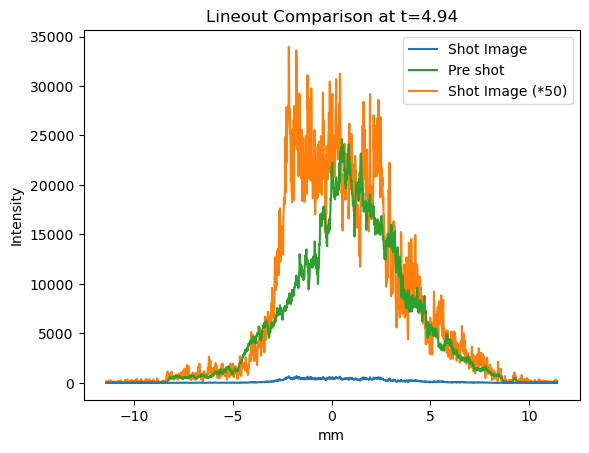

Pre shot time: 4.96
Shot image time: 4.96


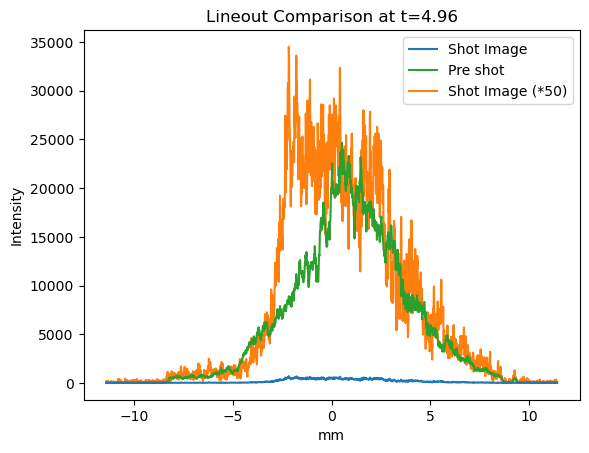

Pre shot time: 4.98
Shot image time: 4.98


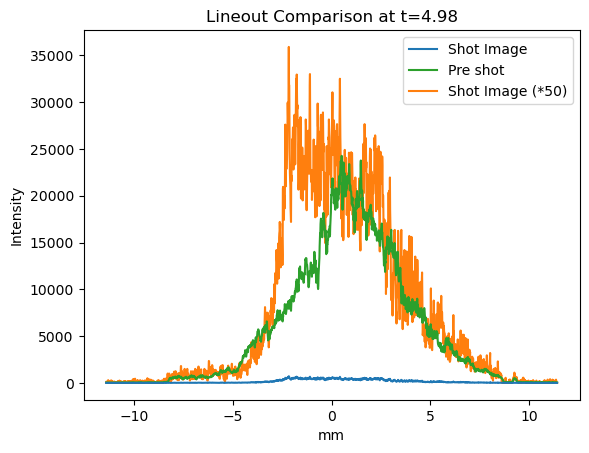

Pre shot time: 5.0
Shot image time: 5.0


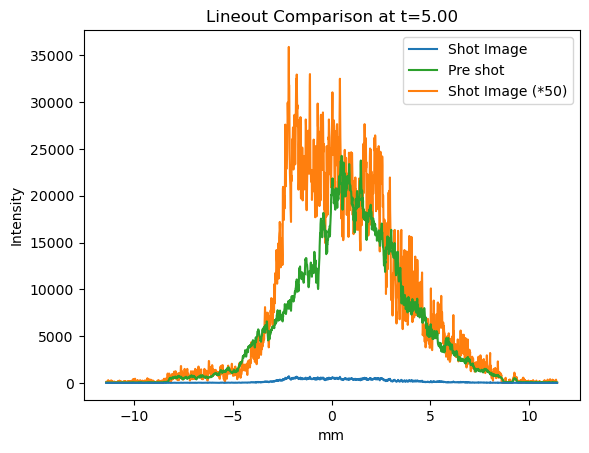

In [14]:
for i in range(len(times_bkgd_img)):
    print(f'Pre shot time: {times_bkgd_img[i]}')
    print(f'Shot image time: {times_bkgd[i]}')
    plt.plot(pos_bkgd_img[i], lineouts_bkgd_img[i], label = 'Shot Image', zorder = 3, color = 'tab:blue')
    plt.plot(pos_bkgd[i], lineouts_bkgd[i], label = 'Pre shot', color = 'tab:green')
    plt.plot(pos_bkgd_img[i], lineouts_bkgd_img[i]*50, label = 'Shot Image (*50)', zorder = 1, color = 'tab:orange')
    plt.title(f'Lineout Comparison at t={times_bkgd_img[i]:.2f}')
    plt.legend()
    plt.xlabel('mm')
    plt.ylabel('Intensity')
    # plt.xlim(5,10)
    plt.savefig(f'streak_images/background/comparison_t={times_bkgd_img[i]:.2f}.jpg', bbox_inches = 'tight')
    plt.show()

Pre shot time: 3.52
Shot image time: 3.52


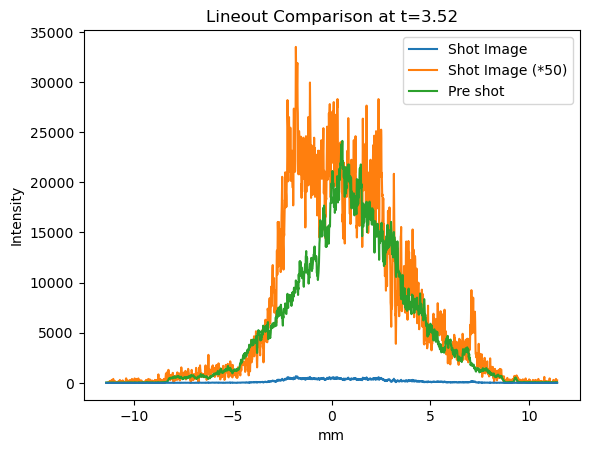

Pre shot time: 3.54
Shot image time: 3.54


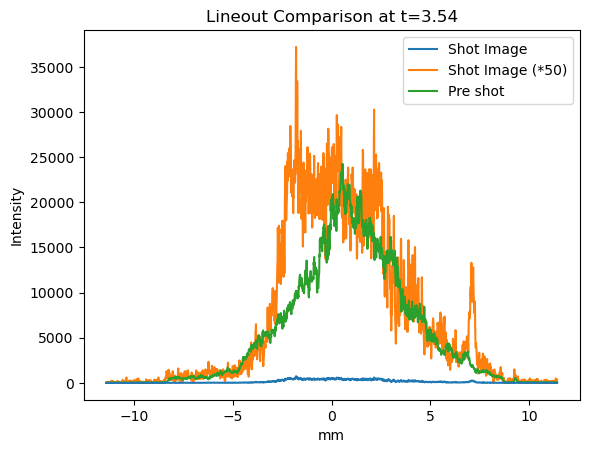

Pre shot time: 3.56
Shot image time: 3.56


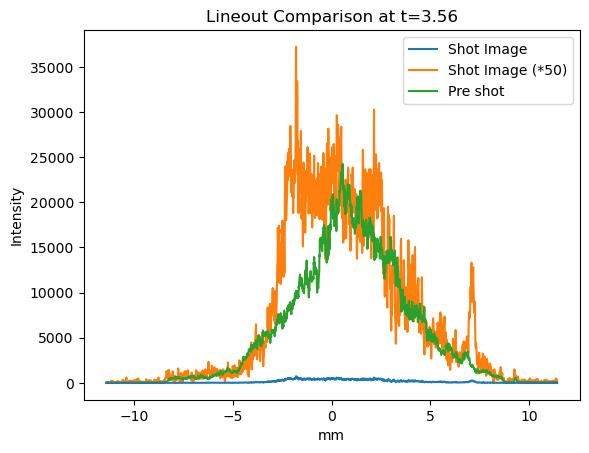

Pre shot time: 3.58
Shot image time: 3.58


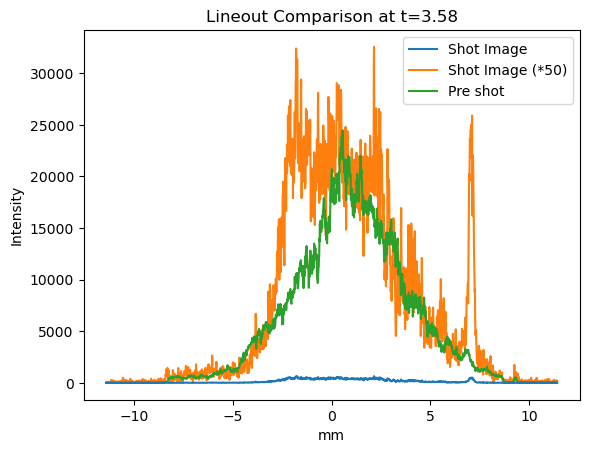

Pre shot time: 3.6
Shot image time: 3.6


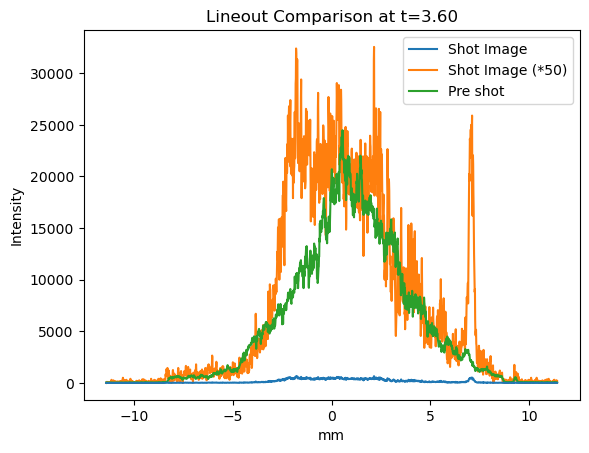

Pre shot time: 3.62
Shot image time: 3.62


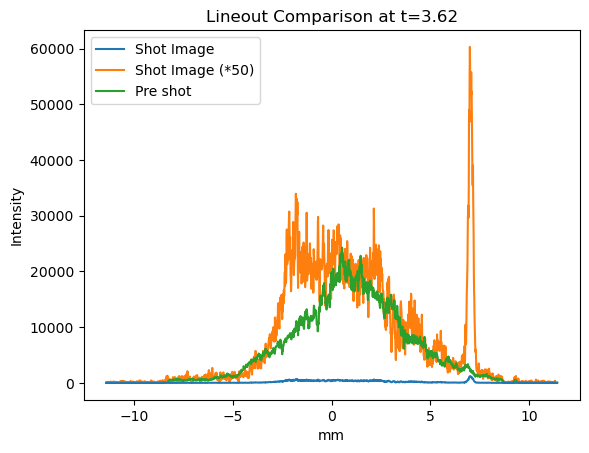

Pre shot time: 3.64
Shot image time: 3.64


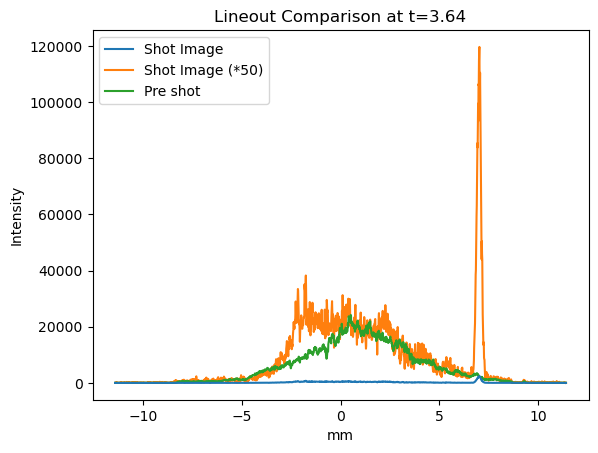

Pre shot time: 3.66
Shot image time: 3.66


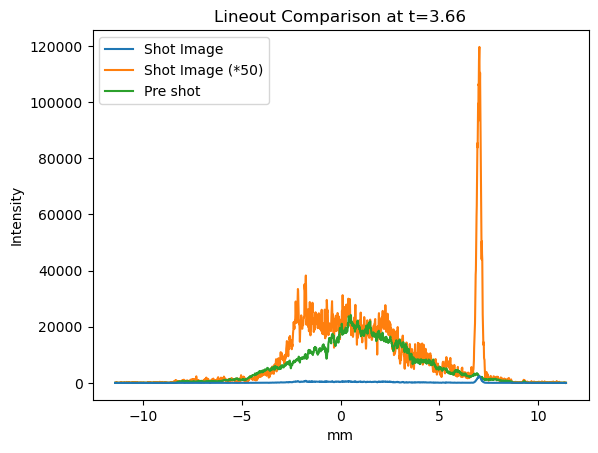

Pre shot time: 3.68
Shot image time: 3.68


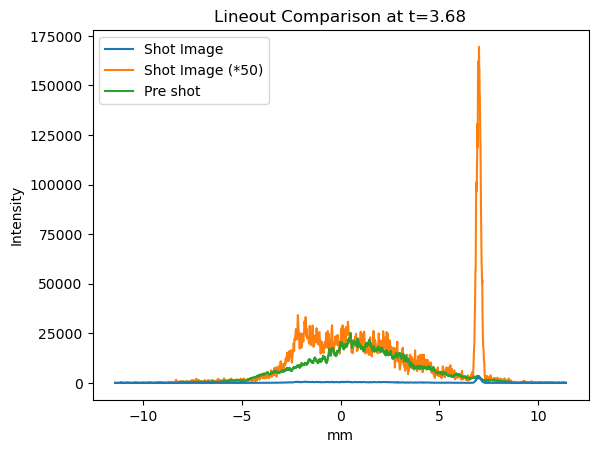

Pre shot time: 3.7
Shot image time: 3.7


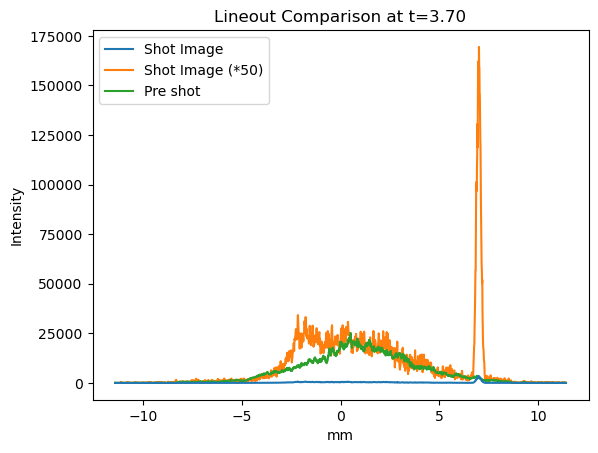

Pre shot time: 3.7199999999999998
Shot image time: 3.7199999999999998


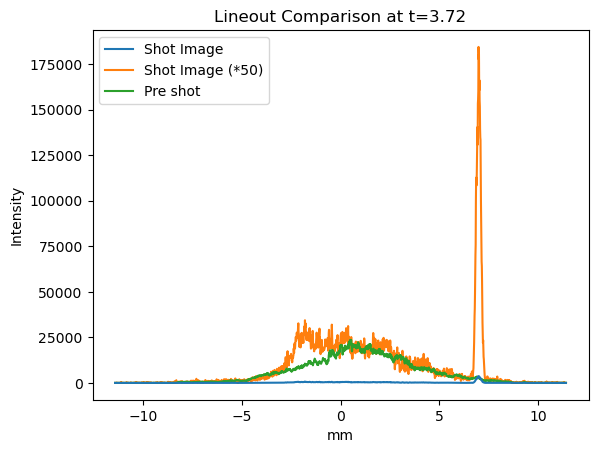

Pre shot time: 3.74
Shot image time: 3.74


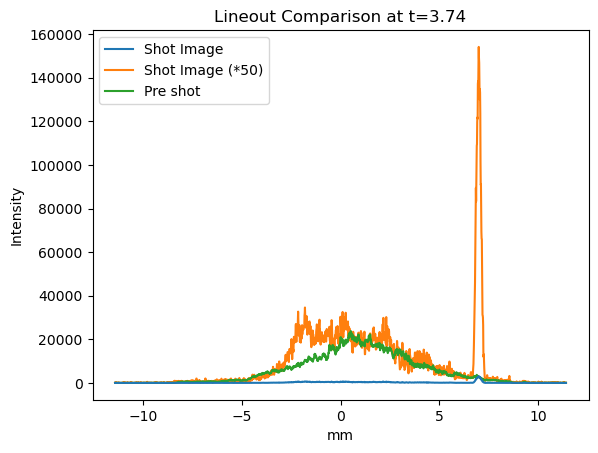

Pre shot time: 3.76
Shot image time: 3.76


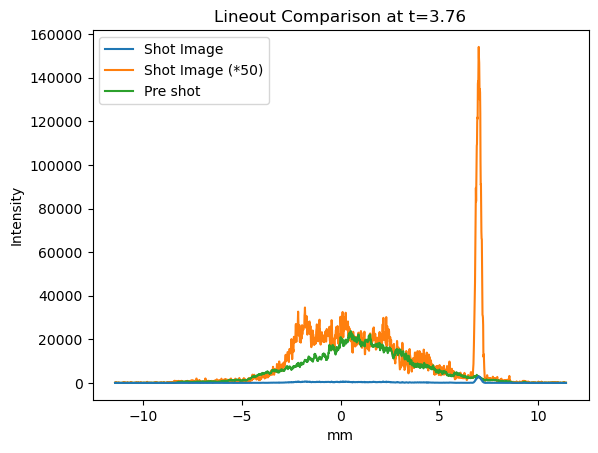

Pre shot time: 3.7800000000000002
Shot image time: 3.7800000000000002


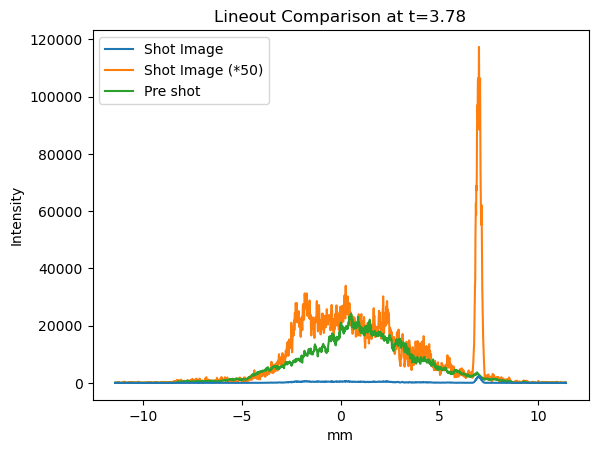

Pre shot time: 3.8
Shot image time: 3.8


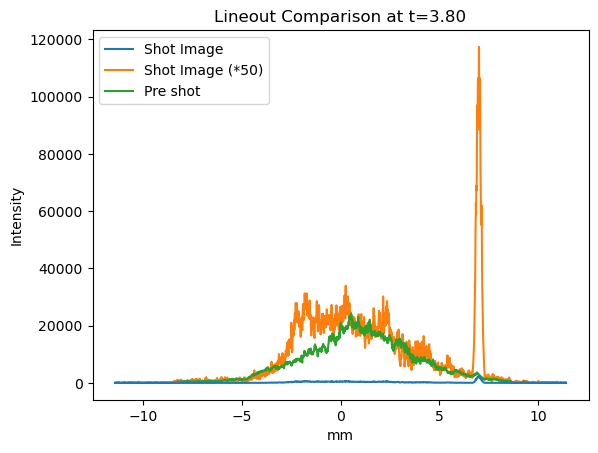

Pre shot time: 3.8200000000000003
Shot image time: 3.8200000000000003


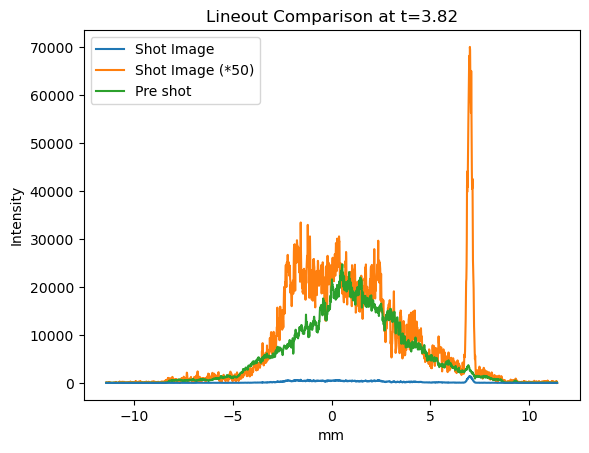

Pre shot time: 3.84
Shot image time: 3.84


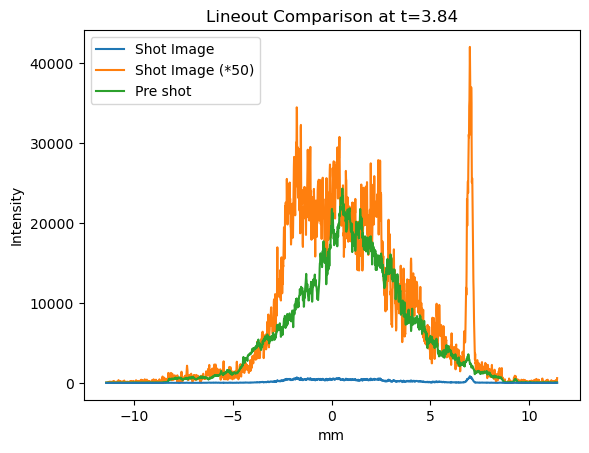

Pre shot time: 3.86
Shot image time: 3.86


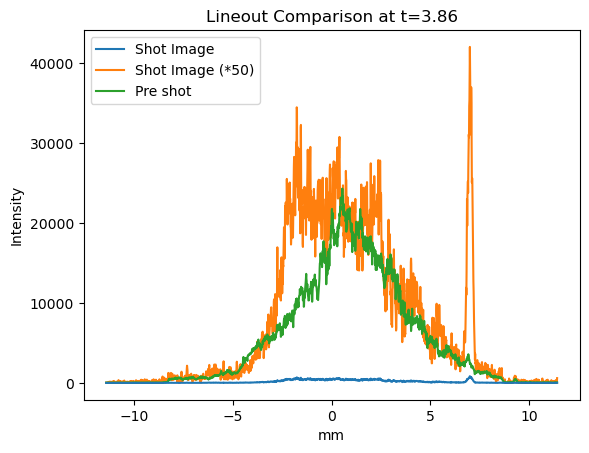

Pre shot time: 3.88
Shot image time: 3.88


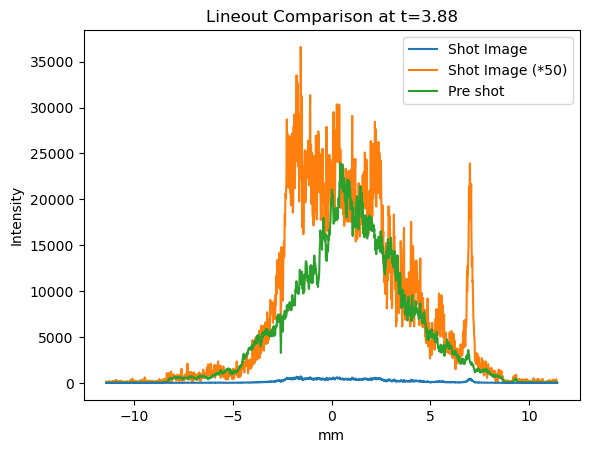

Pre shot time: 3.9
Shot image time: 3.9


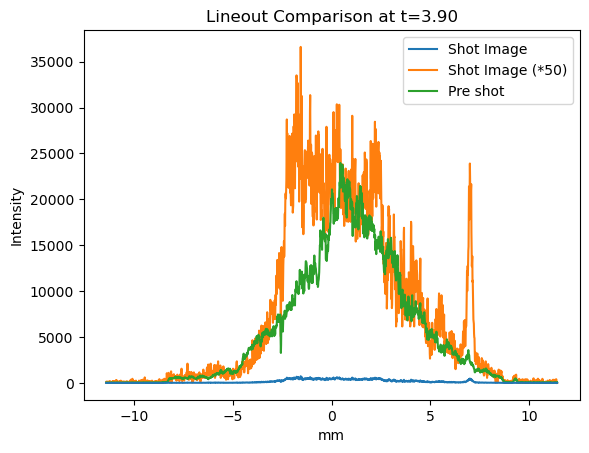

Pre shot time: 3.92
Shot image time: 3.92


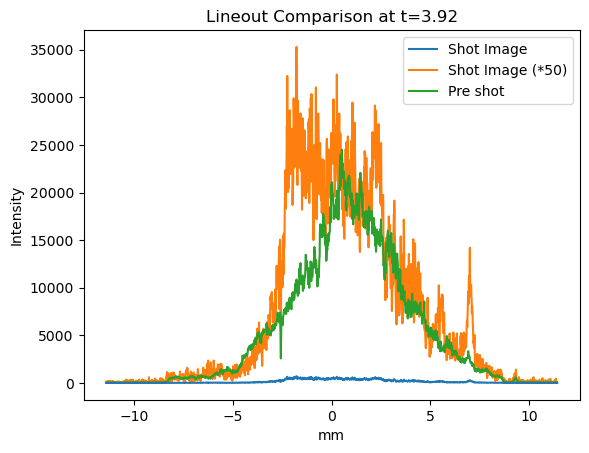

Pre shot time: 3.94
Shot image time: 3.94


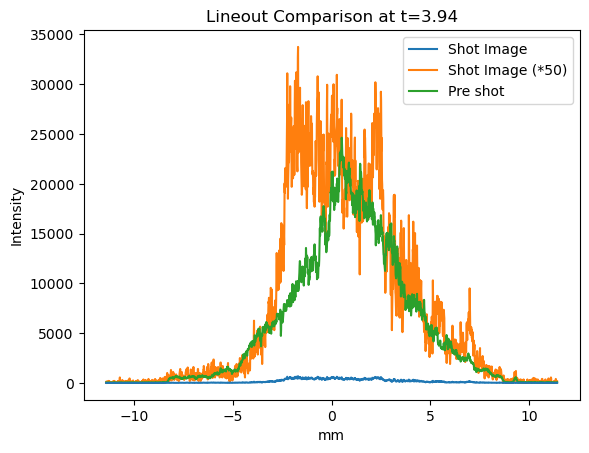

Pre shot time: 3.96
Shot image time: 3.96


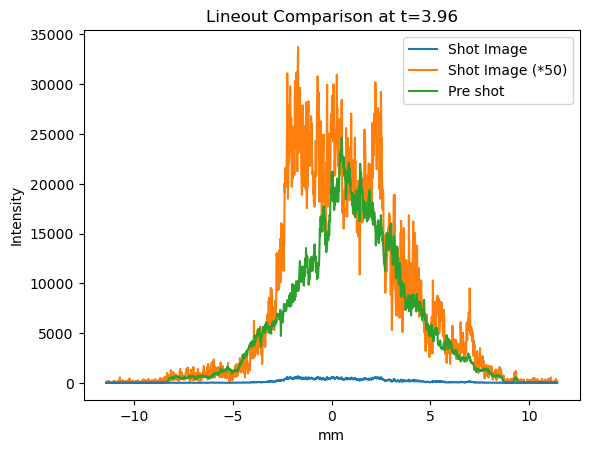

Pre shot time: 3.98
Shot image time: 3.98


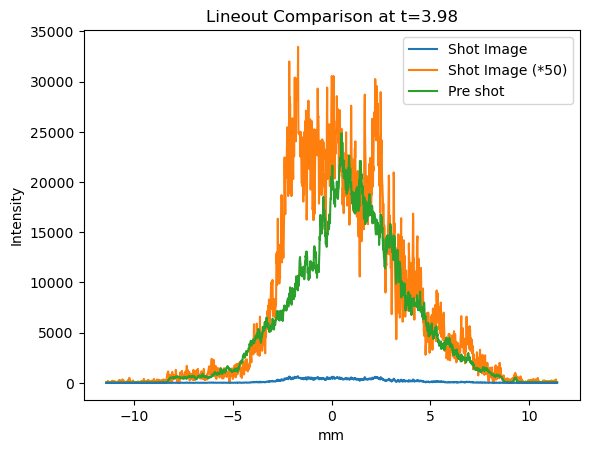

In [95]:
for i in range(len(times_bkgd_img_ret)):
    print(f'Pre shot time: {times_bkgd_img_ret[i]}')
    print(f'Shot image time: {times_bkgd_ret[i]}')
    plt.plot(pos_bkgd_img_ret[i], lineouts_bkgd_img_ret[i], label = 'Shot Image', zorder = 3, color = 'tab:blue')
    plt.plot(pos_bkgd_img_ret[i], lineouts_bkgd_img_ret[i]*50, label = 'Shot Image (*50)', zorder = 1, color = 'tab:orange')
    plt.plot(pos_bkgd_ret[i], lineouts_bkgd_ret[i], label = 'Pre shot', color = 'tab:green')
    plt.title(f'Lineout Comparison at t={times_bkgd_img_ret[i]:.2f}')
    plt.legend()
    plt.xlabel('mm')
    plt.ylabel('Intensity')
    # plt.xlim(5,10)
    plt.savefig(f'streak_images/background/comparison_t={times_bkgd_img_ret[i]:.2f}.jpg', bbox_inches = 'tight')
    plt.show()